# Assignment 3: Hyperparameter Tuning a Fully Connected Network on CIFAR-10

**Student:** Anush Goel  
**NUID:** 002570173  
**Topic:** Controlled experiments, random search and Bayesian optimization for a dense neural network

---

### What this notebook does

The brief asks for controlled experimentation rather than a leaderboard number, so I have set the notebook up the way I would set up a small research study. Every experiment changes one thing at a time, shares the same seed, data split and evaluation procedure, and logs its full training history. Decisions are made on validation data only; the test set is opened exactly once, in Step 7.

Three habits run through the whole notebook and go a little past the brief:

1. **A noise band for validation accuracy.** With 5,000 validation images, accuracy has sampling error of its own. I estimate how large a difference has to be before it is worth taking seriously, and I back the key comparisons with paired McNemar tests on the validation predictions.
2. **Fair axes for batch-size comparisons.** Curves are plotted against epochs, weight updates and wall-clock time, because each axis tells a different story.
3. **A Bayesian search that is actually Bayesian.** Out of the box, both Optuna and KerasTuner spend their first several trials sampling at random. With an eight-trial budget that would quietly turn "Bayesian optimization" into a second random search, so I configure the sampler so that most trials are model-guided.

All results and figures are exported to a `results/` folder. From there, `make report` builds the GitHub research report (`REPORT.md`), and the same folder drives the interactive Streamlit dashboard (`streamlit_app.py`).

### Roadmap

| Step | Question it answers |
|---|---|
| 1 | Is the data split clean, stratified and reproducible? |
| 2 | How does the fixed baseline train, and where does it start to overfit? |
| 3 | How does batch size change convergence, stability and cost? |
| 4 | Does batch normalization help at the selected batch size? |
| 5 | What does an eight-trial random search find? |
| 6 | Does eight-trial Bayesian optimization do better, and at what cost? |
| 7 | Which configuration do I choose, and how does it do on the test set? |
| 8 | What changed between the baseline and the final model? |
| Beyond the brief | Seed robustness check, limitations and recommendations |
| 9 | Final analysis and reflection |

## Setup and reproducibility

Every run is seeded through `keras.utils.set_random_seed`, which seeds Python, NumPy and TensorFlow together, and TensorFlow's op determinism is switched on so that the same seed gives the same weights and the same shuffling order. A GPU runtime is strongly recommended (in Colab: *Runtime → Change runtime type → GPU*); the whole notebook takes roughly an hour on a T4.

In [1]:
# --- Packages ---------------------------------------------------------------
# TensorFlow, scikit-learn, pandas, matplotlib and SciPy ship with Colab.
# Optuna is installed on the fly if it is missing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("optuna") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna"])

import gc, itertools, json, math, re, shutil, time, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10
import optuna

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=getattr(optuna.exceptions, "ExperimentalWarning", Warning))
optuna.logging.set_verbosity(optuna.logging.WARNING)

gpus = tf.config.list_physical_devices("GPU")
try:
    HARDWARE = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU") if gpus else "CPU"
except Exception:
    HARDWARE = "GPU"
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | Optuna {optuna.__version__} | running on {HARDWARE}")

TensorFlow 2.21.0 | Keras 3.13.2 | Optuna 5.0.0 | running on NVIDIA L4


In [2]:
# --- Experiment configuration: one place to change anything -----------------
SEED = 42
VAL_SIZE = 5_000
MAX_EPOCHS = 30                  # same cap for every experiment and every search trial
BASELINE_BATCH = 128
BATCH_SIZES = [32, 128, 512]
N_TRIALS = 8                     # identical budget for random search and Bayesian optimization
SEARCH_PATIENCE = 8              # early-stopping patience, identical for every search trial
TPE_STARTUP_TRIALS = 3           # random warm-up trials before TPE starts modelling
RUN_LR_EXTENSION = True          # optional Step 4 extension (higher learning rate)
RUN_SEED_CHECK = True            # robustness check of the final configuration (validation only)
SEED_CHECK_SEEDS = [7, 2024, 31337]
DETERMINISTIC = True

# Thresholds used to label search trials (defined before any trial is run)
FAIL_ACC = 0.20                  # best validation accuracy below twice chance level
UNSTABLE_JITTER = 0.02           # typical epoch-to-epoch swing in validation accuracy above 2 pp
UNSTABLE_DROP = 0.05             # any single-epoch drop in validation accuracy of 5 pp or more

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
RESULTS_DIR = Path("results")
FIG_DIR = RESULTS_DIR / "figures"          # every figure is also saved here for the GitHub report
for d in (RESULTS_DIR / "weights", FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def set_seed(seed: int = SEED) -> None:
    """Seed Python, NumPy and TensorFlow in one call."""
    keras.utils.set_random_seed(seed)

set_seed(SEED)
if DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()

In [3]:
# --- Visual identity and small helpers --------------------------------------
PALETTE = {
    "baseline": "#7A8494", "bs32": "#9CC3E6", "bs64": "#6FA6D8", "bs128": "#4C8BC9",
    "bs256": "#2F6DAE", "bs512": "#1E4E8C", "bn": "#4F46B8", "random": "#B83280",
    "bayes": "#0F7C80", "final": "#C8961B", "train": "#9AA3B0", "ink": "#17212B",
    "grid": "#E3E7EA", "alert": "#B83280",
}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#9AA3B0",
    "axes.labelcolor": PALETTE["ink"], "axes.titleweight": "bold", "axes.titlesize": 11.5,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": PALETTE["grid"],
    "grid.linewidth": 0.8, "xtick.color": "#4A5563", "ytick.color": "#4A5563",
    "legend.frameon": False, "font.size": 10,
})
HP_LABELS = {"learning_rate": "Learning rate", "batch_size": "Batch size",
             "layers": "Hidden layers", "units": "Units per layer", "dropout": "Dropout"}

def pct(x, d=2):  return f"{100 * x:.{d}f}%"
def pp(x, d=2):   return f"{100 * x:.{d}f} pp"
def spp(x, d=2):  return f"{100 * x:+.{d}f} pp"
def fmt_p(p):     return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
def join_and(items):
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]

def finish(fig, title, tight=True):
    """Left-aligned figure title, tidy layout, save a PNG for the report, render."""
    fig.suptitle(title, x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=PALETTE["ink"])
    if tight:
        fig.tight_layout(rect=(0, 0, 1, 0.94))
    number = re.match(r"Figure (\d+)\.", title)
    if number:
        fig.savefig(FIG_DIR / f"figure_{int(number.group(1)):02d}.png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

def show_table(df, caption=None, formats=None):
    """Display a DataFrame with per-column string formats (no Styler dependency)."""
    out = df.copy()
    for col, f in (formats or {}).items():
        if col in out:
            out[col] = out[col].map(lambda v: f.format(v) if pd.notna(v) else "—")
    if caption:
        display(Markdown(f"**{caption}**"))
    display(out)

# Data-driven sentences. They are printed as evidence after each experiment, saved to
# results/narrative.json, and used to fill the {{PLACEHOLDERS}} in the written analysis.
NARRATIVE = {}
def note(**items):
    NARRATIVE.update({k: str(v) for k, v in items.items()})
    (RESULTS_DIR / "narrative.json").write_text(json.dumps(NARRATIVE, indent=2, ensure_ascii=False))

def evidence(title, keys):
    body = "\n".join(f"- {NARRATIVE[k]}" for k in keys)
    display(Markdown(f"**Evidence from this run: {title}**\n\n{body}"))

def describe(cfg):
    """Plain-English description of a configuration."""
    hidden = list(cfg["hidden"])
    if len(set(hidden)) == 1:
        arch = f"{len(hidden)} hidden layers of {hidden[0]} units"
    else:
        arch = "hidden layers of " + ", ".join(map(str, hidden[:-1])) + f" and {hidden[-1]} units"
    lr = cfg["learning_rate"] or 0.001
    bn = "with" if cfg["batch_norm"] else "without"
    return (f"{arch}, {bn} batch normalization, dropout {cfg['dropout']:g}, "
            f"learning rate {lr:g} and batch size {cfg['batch_size']}")

## Step 1: Prepare the data

CIFAR-10 contains 60,000 colour images of 32 × 32 pixels in ten balanced classes (Krizhevsky, 2009). I flatten each image into 3,072 values, scale pixels to [0, 1] and carve a stratified 5,000-image validation set out of the 50,000 training images with a fixed seed. The official 10,000-image test set is set aside and not touched until Step 7. Labels stay as integers, which is what sparse categorical cross-entropy expects.

In [4]:
(X_train_raw, y_train_raw), (X_test_raw, y_test) = cifar10.load_data()
y_train_raw, y_test = y_train_raw.ravel().astype("int64"), y_test.ravel().astype("int64")

# Stratified, seeded split of the 50,000 training images into 45,000 / 5,000
train_idx, val_idx = train_test_split(
    np.arange(len(X_train_raw)), test_size=VAL_SIZE,
    stratify=y_train_raw, shuffle=True, random_state=SEED)

def flatten_and_scale(images):
    """32 x 32 x 3 uint8 images -> 3,072 float32 features in [0, 1]."""
    return images.reshape(len(images), -1).astype("float32") / 255.0

X_train, y_train = flatten_and_scale(X_train_raw[train_idx]), y_train_raw[train_idx]
X_val, y_val = flatten_and_scale(X_train_raw[val_idx]), y_train_raw[val_idx]
X_test = flatten_and_scale(X_test_raw)
N_TRAIN, N_VAL = len(X_train), len(X_val)

# Sanity checks: sizes, value range, and no overlap between train and validation
assert X_train.shape == (45_000, 3072) and X_val.shape == (5_000, 3072) and X_test.shape == (10_000, 3072)
assert X_train.min() >= 0.0 and X_train.max() <= 1.0
assert len(np.intersect1d(train_idx, val_idx)) == 0

counts = pd.DataFrame({"train": np.bincount(y_train, minlength=10),
                       "validation": np.bincount(y_val, minlength=10),
                       "test": np.bincount(y_test, minlength=10)}, index=CLASS_NAMES)
summary = pd.DataFrame({
    "Samples": [N_TRAIN, N_VAL, len(X_test)],
    "Features": [X_train.shape[1]] * 3,
    "Pixel min": [X_train.min(), X_val.min(), X_test.min()],
    "Pixel max": [X_train.max(), X_val.max(), X_test.max()],
    "Pixel mean": [X_train.mean(), X_val.mean(), X_test.mean()],
    "Images per class": [f"{c.min()}–{c.max()}" for c in (counts["train"], counts["validation"], counts["test"])],
}, index=["Train", "Validation", "Test"])
show_table(summary, "Data split summary", {"Pixel min": "{:.3f}", "Pixel max": "{:.3f}", "Pixel mean": "{:.4f}"})

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2110s 12us/step


**Data split summary**

,Samples,Features,Pixel min,Pixel max,Pixel mean,Images per class
Train,45000,3072,0.000,1.000,0.4732,4500–4500
Validation,5000,3072,0.000,1.000,0.4745,500–500
Test,10000,3072,0.000,1.000,0.4766,1000–1000


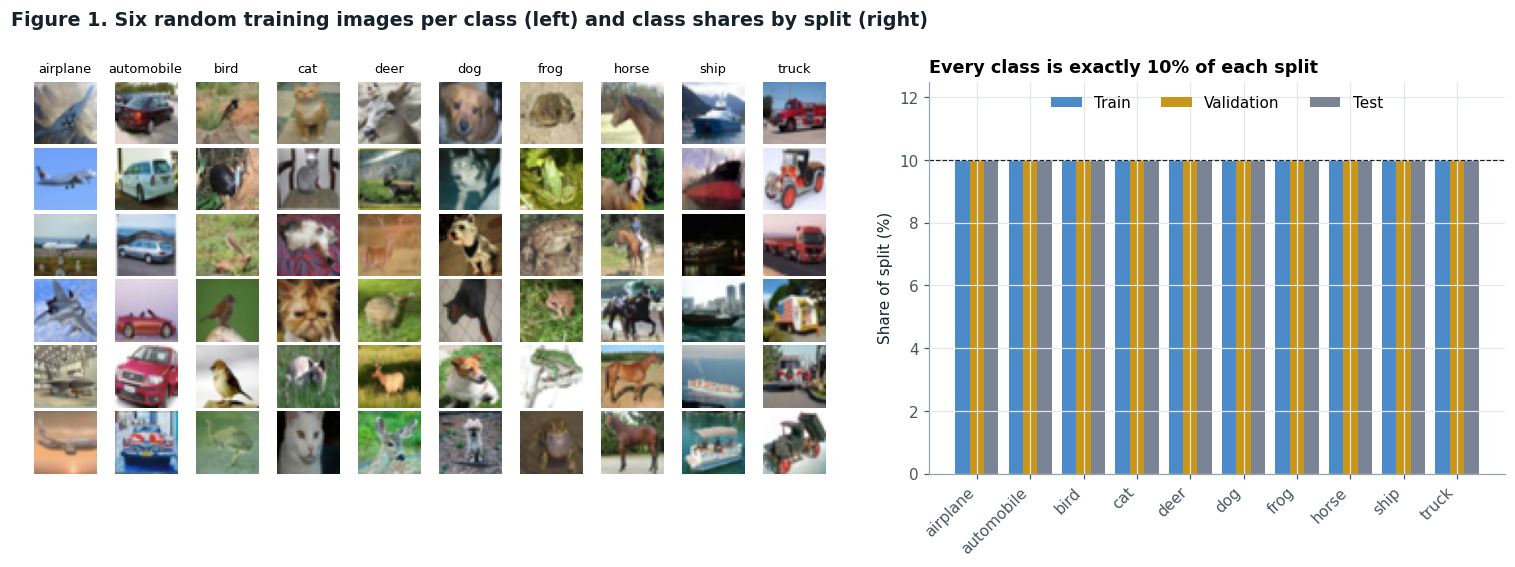

In [5]:
# Figure 1: what the network sees, and evidence that the split is balanced
rng = np.random.default_rng(SEED)
sample_grid = np.zeros((6, 10, 32, 32, 3), dtype=np.uint8)
fig = plt.figure(figsize=(14, 5.4))
outer = fig.add_gridspec(1, 2, width_ratios=[1.4, 1], wspace=0.14, left=0.02, right=0.98, top=0.86, bottom=0.2)
gallery = outer[0].subgridspec(6, 10, wspace=0.06, hspace=0.06)
for c in range(10):
    picks = rng.choice(np.where(y_train == c)[0], 6, replace=False)
    for r, i in enumerate(picks):
        sample_grid[r, c] = X_train_raw[train_idx[i]]
        ax = fig.add_subplot(gallery[r, c])
        ax.imshow(sample_grid[r, c]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values(): s.set_visible(False)
        if r == 0:
            ax.set_title(CLASS_NAMES[c], fontsize=8.5, fontweight="normal", loc="center")

ax = fig.add_subplot(outer[1])
share = counts / counts.sum()
x, w = np.arange(10), 0.27
for k, (col, color) in enumerate(zip(share.columns, [PALETTE["bs128"], PALETTE["final"], PALETTE["baseline"]])):
    ax.bar(x + (k - 1) * w, share[col] * 100, w, label=col.capitalize(), color=color)
ax.axhline(10, color=PALETTE["ink"], lw=0.8, ls="--")
ax.set_xticks(x, CLASS_NAMES, rotation=45, ha="right")
ax.set_ylim(0, 12.5); ax.set_ylabel("Share of split (%)")
ax.set_title("Every class is exactly 10% of each split")
ax.legend(ncol=3, loc="upper center")
finish(fig, "Figure 1. Six random training images per class (left) and class shares by split (right)", tight=False)

np.savez_compressed(RESULTS_DIR / "data_samples.npz", grid=sample_grid)
counts.to_csv(RESULTS_DIR / "class_counts.csv")

### Why normalize, and why hold out a validation set?

**Normalization.** Raw pixels run from 0 to 255. Fed in at that scale, the first layer's pre-activations would be hundreds of times larger than standard weight initializers are designed for. That pushes ReLU units into extreme regimes, inflates early gradients, and makes the effective step size depend on the units of the input rather than on the optimizer's settings. Scaling inputs to a small, consistent range keeps the optimization problem well conditioned and lets the initialization behave as intended (Glorot & Bengio, 2010; LeCun et al., 2012). Dividing by 255 is the simplest transform that achieves this, and because it is a fixed constant it treats training, validation and test images identically without leaking any statistics from the evaluation data.

**A separate validation set.** Every decision in this notebook (the batch size, whether to use batch normalization, which search trial wins, which epoch to keep) is a form of fitting. If those choices were made on the test set, test accuracy would stop being an unbiased estimate of performance on new data and would instead reward whichever configuration happened to suit those particular 10,000 images (Raschka, 2018). The validation split absorbs all of that selection pressure and leaves the test set as a clean, one-time check. Stratifying the split keeps exactly 500 images per class in validation, so validation accuracy is not tilted toward classes that happened to be over-sampled.

**How precise is a validation score?** Validation accuracy is itself an estimate from a finite sample. With *n* = 5,000 images and accuracy near 50%, its standard error is about √(0.5 × 0.5 / 5,000) ≈ 0.71 percentage points (pp), and the standard error of a *difference* between two independently evaluated models is about √2 × 0.71 ≈ 1.0 pp. I use this **1-pp noise band** throughout as a practical threshold: gaps smaller than that are treated as "too close to call" rather than as evidence that one setting is better. Because every model is scored on the *same* validation images, I also run paired McNemar tests for the key comparisons, which are more sensitive than the noise band alone (Dietterich, 1998).

In [6]:
NOISE_SE = math.sqrt(0.25 / N_VAL)          # worst-case standard error of one validation accuracy
NOISE_BAND = math.sqrt(2) * NOISE_SE        # approximate standard error of a difference between two models
print(f"SE of one validation accuracy: {pp(NOISE_SE)} | noise band for comparisons: {pp(NOISE_BAND)}")

def mcnemar(correct_a, correct_b):
    """Exact McNemar test on paired validation predictions. Returns (a-only, b-only, p-value)."""
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    p = 1.0 if b + c == 0 else binomtest(min(b, c), b + c, 0.5).pvalue
    return b, c, p

def verdict(diff, p):
    """Plain-language reading of an accuracy difference and its McNemar p-value."""
    big, sig = abs(diff) > NOISE_BAND, p < 0.05
    if big and sig:
        return f"a difference that clears both the 1-pp noise band and a paired McNemar test ({fmt_p(p)})"
    if sig:
        return f"a difference inside the noise band that the more sensitive paired McNemar test still flags as significant ({fmt_p(p)})"
    if big:
        return f"a difference larger than the noise band that the paired McNemar test does not confirm ({fmt_p(p)})"
    return f"a difference inside the noise band that the paired McNemar test cannot distinguish from chance ({fmt_p(p)})"

SE of one validation accuracy: 0.71 pp | noise band for comparisons: 1.00 pp


## Step 2: Build the baseline model

The baseline is fixed by the brief: 3,072 → 512 → 256 → 128 → 10, ReLU hidden layers, a softmax output, no dropout or batch normalization, Adam with its default settings (learning rate 0.001), batch size 128 and 30 epochs.

The training utility below is shared by every experiment in the notebook, which is what makes the comparisons fair. For each run it re-seeds before the weights are created, times every epoch, keeps an in-memory copy of the weights from the epoch with the best validation accuracy, and stores that epoch's validation predictions for the paired tests. Steps 2 to 4 always train for the full 30 epochs so that the curves show the complete picture, including overfitting. The search trials in Steps 5 and 6 add early stopping with the same patience for every trial.

In [7]:
def make_config(hidden=(512, 256, 128), batch_norm=False, dropout=0.0, learning_rate=None, batch_size=BASELINE_BATCH):
    """learning_rate=None means Adam's default (0.001), compiled exactly as the brief specifies."""
    return dict(hidden=tuple(hidden), batch_norm=batch_norm, dropout=float(dropout),
                learning_rate=learning_rate, batch_size=int(batch_size))

def build_mlp(hidden=(512, 256, 128), batch_norm=False, dropout=0.0, learning_rate=None, name="mlp"):
    """Fully connected classifier. With batch_norm=True each hidden block is Dense -> BatchNorm -> ReLU."""
    inputs = keras.Input(shape=(3072,), name="pixels")
    x = inputs
    for i, units in enumerate(hidden, start=1):
        if batch_norm:
            # The bias is redundant here: BatchNorm's learned shift (beta) plays the same role.
            x = layers.Dense(units, use_bias=False, name=f"dense_{i}")(x)
            x = layers.BatchNormalization(name=f"batchnorm_{i}")(x)
            x = layers.Activation("relu", name=f"relu_{i}")(x)
        else:
            x = layers.Dense(units, activation="relu", name=f"dense_{i}")(x)
        if dropout > 0:
            x = layers.Dropout(dropout, name=f"dropout_{i}")(x)
    outputs = layers.Dense(10, activation="softmax", name="class_probs")(x)
    model = keras.Model(inputs, outputs, name=name)
    optimizer = "adam" if learning_rate is None else keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


class EpochTimer(keras.callbacks.Callback):
    """Wall-clock seconds per epoch (training pass plus validation pass)."""
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.perf_counter() - self._start)


class BestWeights(keras.callbacks.Callback):
    """Keep the weights from the epoch with the highest validation accuracy."""
    def on_train_begin(self, logs=None): self.best, self.best_epoch, self.weights = -np.inf, 0, None
    def on_epoch_end(self, epoch, logs=None):
        acc = (logs or {}).get("val_accuracy", -np.inf)
        if acc > self.best:
            self.best, self.best_epoch, self.weights = acc, epoch + 1, self.model.get_weights()


def classify(rec):
    if rec["diverged"] or rec["best_val_acc"] < FAIL_ACC:
        return "failed"
    if rec["jitter"] > UNSTABLE_JITTER or rec["max_drop"] >= UNSTABLE_DROP:
        return "unstable"
    return "ok"


RUNS = {}          # every experiment's record, keyed by run name
VAL_CORRECT = {}   # per-image validation correctness at each run's best epoch

def train_run(name, config, group, early_stopping=False, seed=SEED, max_epochs=MAX_EPOCHS, save=True):
    """Train one configuration under the shared protocol and return its record."""
    keras.backend.clear_session(); gc.collect()
    set_seed(seed)                                   # seed BEFORE the weights are created
    model = build_mlp(config["hidden"], config["batch_norm"], config["dropout"], config["learning_rate"], name=name)
    timer, best = EpochTimer(), BestWeights()
    callbacks = [timer, best, keras.callbacks.TerminateOnNaN()]
    if early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                                       patience=SEARCH_PATIENCE, restore_best_weights=False))
    start = time.perf_counter()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=max_epochs,
                     batch_size=config["batch_size"], shuffle=True, callbacks=callbacks, verbose=0)
    total_time = time.perf_counter() - start

    h = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    va, vl, ta = (np.array(h.get(k, [np.nan]), dtype=float) for k in ("val_accuracy", "val_loss", "accuracy"))
    diverged = not np.all(np.isfinite(h.get("loss", [np.nan])))
    if best.weights is not None:
        model.set_weights(best.weights)              # keep the best-validation epoch
    VAL_CORRECT[name] = model.predict(X_val, batch_size=2048, verbose=0).argmax(1) == y_val
    if save:
        model.save_weights(str(RESULTS_DIR / "weights" / f"{name}.weights.h5"))

    b = int(np.nanargmax(va)) if np.isfinite(va).any() else 0
    finite_vl = np.isfinite(vl)
    later = np.diff(va[4:]) if len(va) > 6 else np.diff(va)
    rec = dict(
        name=name, group=group, config={**config, "hidden": list(config["hidden"])},
        history=h, epoch_times=list(timer.times), total_time=total_time, epochs_run=len(va),
        updates_per_epoch=math.ceil(N_TRAIN / config["batch_size"]), params=int(model.count_params()),
        best_val_acc=float(va[b]), best_epoch=b + 1, val_loss_at_best=float(vl[b]),
        best_val_loss=float(np.nanmin(vl)) if finite_vl.any() else float("nan"),
        best_loss_epoch=int(np.nanargmin(vl)) + 1 if finite_vl.any() else 0,
        train_acc_at_best=float(ta[b]), gap_at_best=float(ta[b] - va[b]), gap_at_end=float(ta[-1] - va[-1]),
        jitter=float(np.std(later)) if len(later) else 0.0,
        max_drop=float(max(0.0, -np.min(np.diff(va)))) if len(va) > 1 else 0.0,
        diverged=bool(diverged), seed=seed, early_stopping=early_stopping,
    )
    rec["status"] = classify(rec)
    RUNS[name] = rec
    del model; gc.collect()
    return rec


def observe(rec, best_name=None):
    """Short, rule-based 'key observation' for a run (rules fixed before the search)."""
    if rec["status"] == "failed":
        return "Failed: diverged or stayed near chance"
    bits = []
    if best_name == rec["name"]:
        bits.append("best in this search")
    if rec["best_epoch"] <= 5:
        bits.append(f"peaked early (epoch {rec['best_epoch']})")
    elif rec["best_epoch"] >= MAX_EPOCHS - 1:
        bits.append("still improving at the epoch cap")
    if rec["status"] == "unstable":
        bits.append(f"noisy validation curve (±{100 * rec['jitter']:.1f} pp per epoch)")
    if rec["gap_at_best"] > 0.15:
        bits.append(f"large train–val gap ({100 * rec['gap_at_best']:.0f} pp)")
    elif rec["gap_at_best"] < 0.03:
        bits.append("small train–val gap, capacity-limited")
    if not bits:
        bits.append("steady training with a moderate train–val gap")
    text = "; ".join(bits[:3])
    return text[0].upper() + text[1:]

In [8]:
BASELINE_CFG = make_config()
build_mlp(name="baseline").summary()
base = train_run("baseline", BASELINE_CFG, group="Step 2: baseline")
print(f"Baseline: best val acc {pct(base['best_val_acc'])} at epoch {base['best_epoch']} | "
      f"best val loss {base['best_val_loss']:.4f} at epoch {base['best_loss_epoch']} | "
      f"{base['total_time']:.0f}s on {HARDWARE}")

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ pixels (InputLayer)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probs (Dense)             │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

Baseline: best val acc 48.68% at epoch 21 | best val loss 1.4942 at epoch 11 | 54s on NVIDIA L4


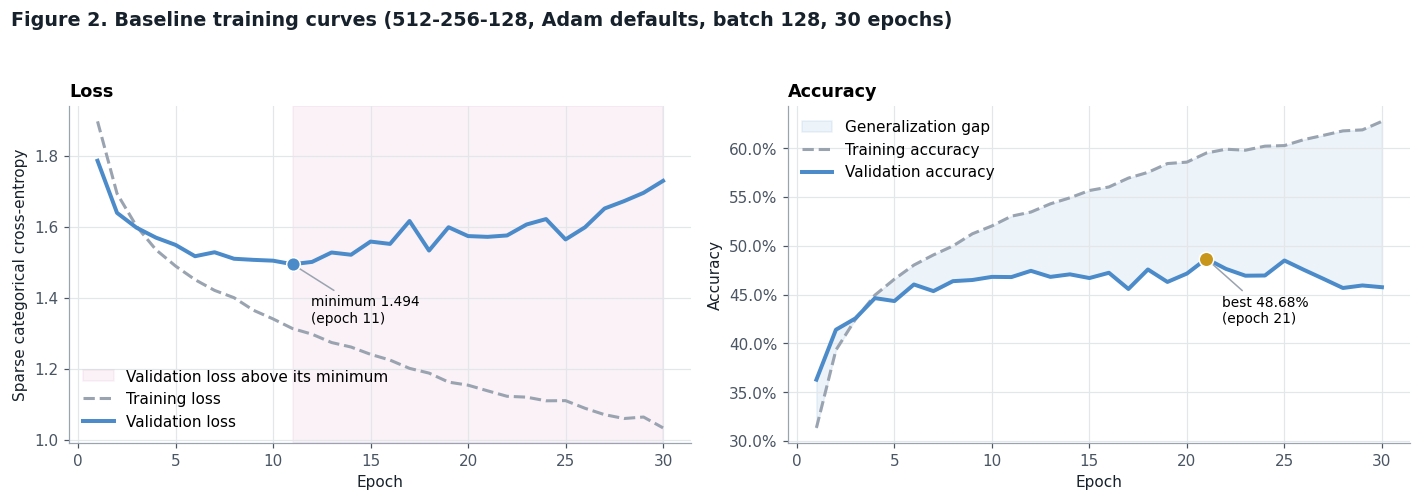

In [9]:
# Figure 2: baseline loss and accuracy curves
h = base["history"]; ep = np.arange(1, base["epochs_run"] + 1)
va, vl, ta, tl = (np.array(h[k]) for k in ("val_accuracy", "val_loss", "accuracy", "loss"))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))

e_min = base["best_loss_epoch"]
ax1.axvspan(e_min, ep[-1], color=PALETTE["alert"], alpha=0.06, label="Validation loss above its minimum")
ax1.plot(ep, tl, color=PALETTE["train"], lw=2, ls="--", label="Training loss")
ax1.plot(ep, vl, color=PALETTE["bs128"], lw=2.6, label="Validation loss")
ax1.scatter([e_min], [vl[e_min - 1]], s=80, color=PALETTE["bs128"], edgecolor="white", zorder=5)
ax1.annotate(f"minimum {vl[e_min - 1]:.3f}\n(epoch {e_min})", (e_min, vl[e_min - 1]), xytext=(12, -38),
             textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="-", color="#9AA3B0"))
ax1.set(xlabel="Epoch", ylabel="Sparse categorical cross-entropy", title="Loss")
ax1.legend(loc="best")

e_b = base["best_epoch"]
ax2.fill_between(ep, va, ta, color=PALETTE["bs128"], alpha=0.10, label="Generalization gap")
ax2.plot(ep, ta, color=PALETTE["train"], lw=2, ls="--", label="Training accuracy")
ax2.plot(ep, va, color=PALETTE["bs128"], lw=2.6, label="Validation accuracy")
ax2.scatter([e_b], [va[e_b - 1]], s=90, color=PALETTE["final"], edgecolor="white", zorder=5)
ax2.annotate(f"best {pct(va[e_b - 1])}\n(epoch {e_b})", (e_b, va[e_b - 1]), xytext=(10, -42),
             textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="-", color="#9AA3B0"))
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
ax2.legend(loc="upper left")
finish(fig, "Figure 2. Baseline training curves (512-256-128, Adam defaults, batch 128, 30 epochs)")

In [10]:
# Turn the baseline curves into evidence for the written analysis
n = base["epochs_run"]
rise = (vl[-1] - base["best_val_loss"]) / base["best_val_loss"]
ups = int(np.sum(np.diff(tl) > 0))
stab_word = "stable" if base["jitter"] < 0.01 else ("moderately noisy" if base["jitter"] < UNSTABLE_JITTER else "unstable")

train_s = (f"Training loss decreased in every one of the {n} epochs, from {tl[0]:.3f} to {tl[-1]:.3f}, and training accuracy climbed to {pct(ta[-1])}."
           if ups == 0 else
           f"Training loss fell from {tl[0]:.3f} to {tl[-1]:.3f}, rising in only {ups} of {n - 1} epoch-to-epoch steps, and training accuracy climbed to {pct(ta[-1])}.")
acc_s = (f"Validation accuracy behaved differently: it peaked at {pct(base['best_val_acc'])} in epoch {e_b} and finished at {pct(va[-1])}, so the {n - e_b} epochs after the peak bought nothing on unseen data."
         if e_b < n else
         f"Validation accuracy was still at its best ({pct(base['best_val_acc'])}) in the final epoch.")
if e_min <= n - 3 and rise > 0.05:
    trend_s = (f"Validation loss reached its minimum of {base['best_val_loss']:.3f} at epoch {e_min} and then climbed {rise:.0%} by epoch {n} "
               f"while training loss kept falling, which is the classic signature of overfitting.")
elif rise > 0.01:
    trend_s = f"Validation loss reached its minimum of {base['best_val_loss']:.3f} at epoch {e_min} and drifted up by {rise:.0%} by epoch {n}, a mild sign of overfitting."
else:
    trend_s = f"Validation loss was still close to its minimum ({base['best_val_loss']:.3f}) at epoch {n}, so overfitting in loss terms stayed limited within 30 epochs."
gap1 = ta[0] - va[0]
gap_s = (f"The gap between training and validation accuracy widened from {pp(gap1)} after the first epoch to {pp(base['gap_at_end'])} "
         f"by epoch {n} ({pct(ta[-1])} versus {pct(va[-1])}).")
stab_s = (f"After the first five epochs, validation accuracy moved by a typical ±{100 * base['jitter']:.2f} pp from one epoch to the next, "
          f"and its largest single-epoch drop was {pp(base['max_drop'])}, so optimization itself was {stab_word}"
          + ("; the problem with the baseline is generalization, not stability." if stab_word != "unstable" else "."))

note(BASE_PARAMS=f"{base['params']:,}", BASE_BEST_VAL_ACC=pct(base["best_val_acc"]), BASE_BEST_EPOCH=e_b,
     BASE_TRAIN_SENTENCE=train_s, BASE_ACC_SENTENCE=acc_s, BASE_TREND_SENTENCE=trend_s,
     BASE_GAP_SENTENCE=gap_s, BASE_STABILITY_SENTENCE=stab_s)
evidence("baseline", ["BASE_TRAIN_SENTENCE", "BASE_ACC_SENTENCE", "BASE_TREND_SENTENCE", "BASE_GAP_SENTENCE", "BASE_STABILITY_SENTENCE"])

**Evidence from this run: baseline**

- Training loss fell from 1.897 to 1.033, rising in only 2 of 29 epoch-to-epoch steps, and training accuracy climbed to 62.77%.
- Validation accuracy behaved differently: it peaked at 48.68% in epoch 21 and finished at 45.76%, so the 9 epochs after the peak bought nothing on unseen data.
- Validation loss reached its minimum of 1.494 at epoch 11 and then climbed 16% by epoch 30 while training loss kept falling, which is the classic signature of overfitting.
- The gap between training and validation accuracy widened from -4.94 pp after the first epoch to 17.01 pp by epoch 30 (62.77% versus 45.76%).
- After the first five epochs, validation accuracy moved by a typical ±0.98 pp from one epoch to the next, and its largest single-epoch drop was 1.66 pp, so optimization itself was stable; the problem with the baseline is generalization, not stability.

### Baseline training behavior

**Convergence.** {{BASE_TRAIN_SENTENCE}} The optimizer had no trouble fitting the training data; Adam's per-parameter step sizes make a network of this kind easy to drive down on training loss (Kingma & Ba, 2015). {{BASE_ACC_SENTENCE}}

**Overfitting and the train–validation gap.** {{BASE_TREND_SENTENCE}} {{BASE_GAP_SENTENCE}} After the first few epochs, the network spends most of its effort memorizing the 45,000 training images rather than learning features that transfer. With {{BASE_PARAMS}} trainable parameters and no regularization at all, that is what I would expect.

**Underfitting, in a specific sense.** It would be wrong to say the baseline underfits the *training* data; it clearly does not. It does, however, underfit the *task*. A dense layer treats the 3,072 inputs as an unordered list, so the network cannot reuse a feature detector across image locations and has to learn "an edge in the top-left" and "an edge in the bottom-right" separately; convolutional layers solve exactly this through parameter sharing (Goodfellow et al., 2016, Chapter 9). That missing inductive bias is why validation accuracy plateaus far below what convolutional networks reach on CIFAR-10, and it sets a realistic expectation for everything that follows: tuning can move this model by a few percentage points, not by tens.

**Stability.** {{BASE_STABILITY_SENTENCE}}

**What this means for the rest of the notebook.** Because validation accuracy peaked at epoch {{BASE_BEST_EPOCH}} of 30, the epoch at which a model is evaluated matters almost as much as its hyperparameters. That is why every run keeps its best-epoch weights, which is a form of early stopping (Prechelt, 1998), and why a regularizer such as dropout (Srivastava et al., 2014) belongs in the search space.

## Step 3: Compare batch sizes

Everything except the batch size is held fixed: same architecture, default Adam, 30 epochs and the same seed. Batch size 128 is the baseline configuration itself, so I reuse the Step 2 run rather than repeating it; with op determinism switched on, a rerun would reproduce it.

Batch size changes how many weight updates happen per epoch, so "epoch 10" means something different for each setting: 1,407 updates at batch size 32 but only 88 at batch size 512. I therefore plot validation loss against three clocks (epochs, cumulative weight updates and wall-clock seconds) and read the results through all three.

In [11]:
BS_RUNS = {}
for bs in BATCH_SIZES:
    if bs == BASELINE_BATCH:
        BS_RUNS[bs] = base           # identical configuration to Step 2
        continue
    BS_RUNS[bs] = train_run(f"bs{bs}", make_config(batch_size=bs), group="Step 3: batch size")
for bs, r in BS_RUNS.items():
    print(f"batch {bs:>3}: best val acc {pct(r['best_val_acc'])} at epoch {r['best_epoch']:>2} | "
          f"{r['updates_per_epoch']:>4} updates/epoch | {r['total_time']:.0f}s")

bs_table = pd.DataFrame([{
    "Batch size": bs,
    "Weight updates per epoch": r["updates_per_epoch"],
    "Best val accuracy": r["best_val_acc"],
    "Best val loss": r["best_val_loss"],
    "Epoch of best val accuracy": r["best_epoch"],
    "Epoch of best val loss": r["best_loss_epoch"],
    "Updates to best val accuracy": r["best_epoch"] * r["updates_per_epoch"],
    "Training time (s)": r["total_time"],
    "Median epoch time (s)": float(np.median(r["epoch_times"])),
    "Val-accuracy jitter (pp)": 100 * r["jitter"],
} for bs, r in BS_RUNS.items()]).set_index("Batch size")
show_table(bs_table, "Batch-size comparison (30 epochs each, default Adam)",
           {"Best val accuracy": "{:.2%}", "Best val loss": "{:.4f}", "Updates to best val accuracy": "{:,}",
            "Training time (s)": "{:.0f}", "Median epoch time (s)": "{:.2f}", "Val-accuracy jitter (pp)": "{:.2f}"})

batch  32: best val acc 46.94% at epoch 15 | 1407 updates/epoch | 176s
batch 128: best val acc 48.68% at epoch 21 |  352 updates/epoch | 54s
batch 512: best val acc 49.78% at epoch 30 |   88 updates/epoch | 22s


**Batch-size comparison (30 epochs each, default Adam)**

,Weight updates per epoch,Best val accuracy,Best val loss,Epoch of best val accuracy,Epoch of best val loss,Updates to best val accuracy,Training time (s),Median epoch time (s),Val-accuracy jitter (pp)
Batch size,,,,,,,,,
32,1407,46.94%,1.5434,15,8,"21,105",176,5.79,0.75
128,352,48.68%,1.4942,21,11,"7,392",54,1.64,0.98
512,88,49.78%,1.4522,30,19,"2,640",22,0.65,0.73


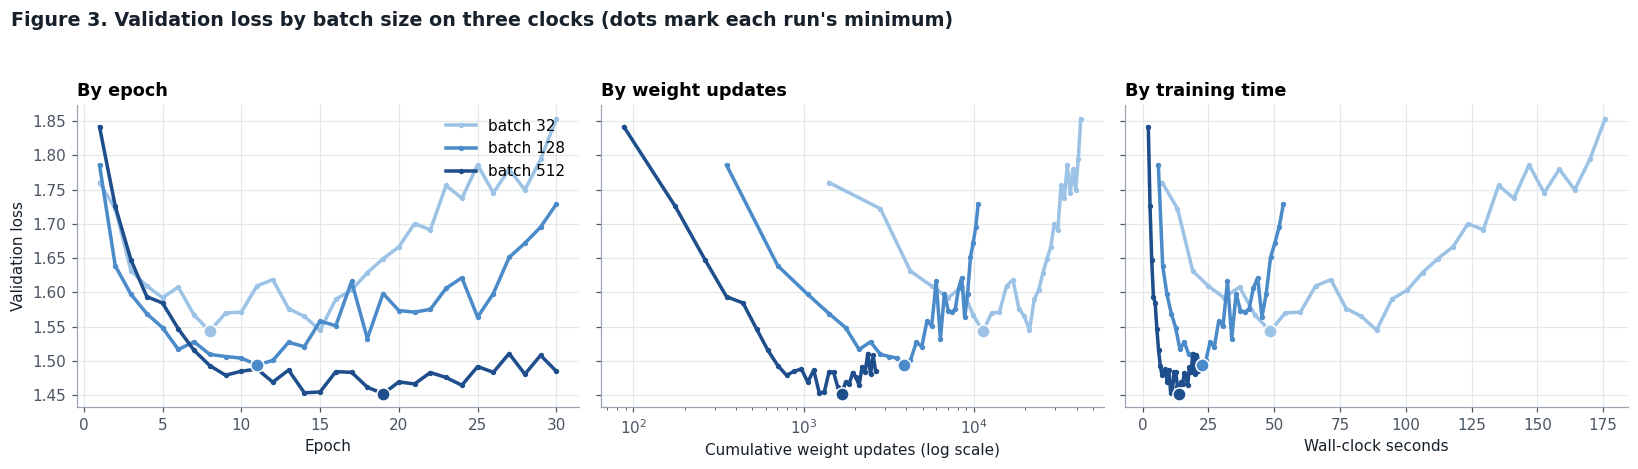

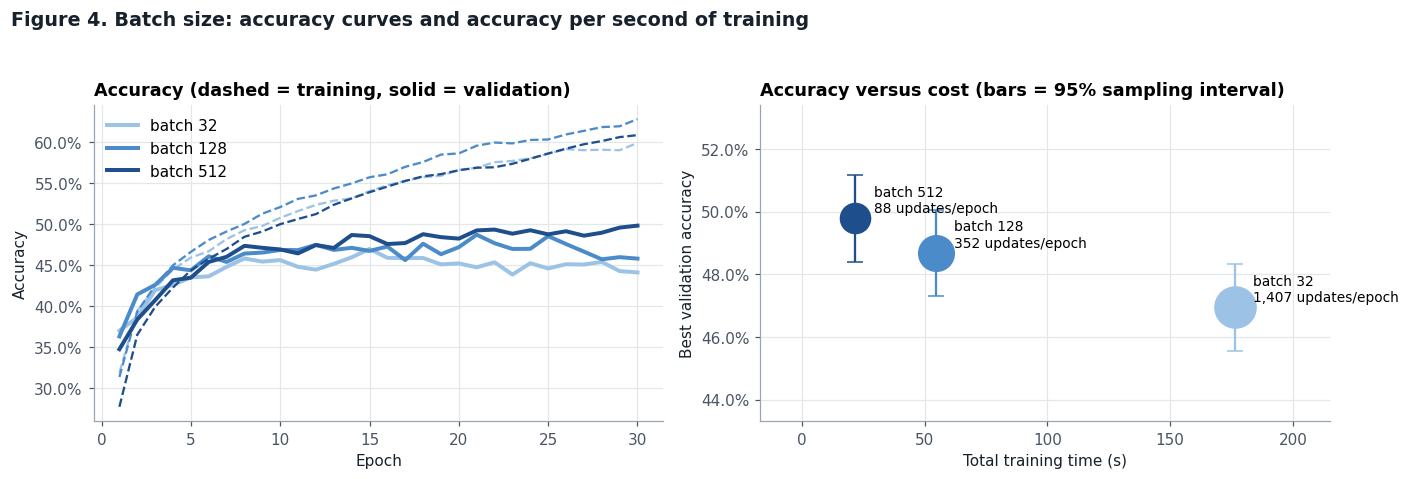

In [12]:
# Figure 3: the same validation-loss curves on three different clocks
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for bs, r in BS_RUNS.items():
    vl_bs = np.array(r["history"]["val_loss"]); ep_bs = np.arange(1, len(vl_bs) + 1)
    clocks = [ep_bs, ep_bs * r["updates_per_epoch"], np.cumsum(r["epoch_times"])]
    k = r["best_loss_epoch"] - 1
    for ax, xs in zip(axes, clocks):
        ax.plot(xs, vl_bs, color=PALETTE[f"bs{bs}"], lw=2.3, marker="o", ms=2.5, label=f"batch {bs}")
        ax.scatter(xs[k], vl_bs[k], s=75, color=PALETTE[f"bs{bs}"], edgecolor="white", zorder=5)
axes[0].set(xlabel="Epoch", ylabel="Validation loss", title="By epoch")
axes[1].set(xlabel="Cumulative weight updates (log scale)", title="By weight updates")
axes[1].set_xscale("log")
axes[2].set(xlabel="Wall-clock seconds", title="By training time")
axes[0].legend(loc="upper right")
finish(fig, "Figure 3. Validation loss by batch size on three clocks (dots mark each run's minimum)")

# Figure 4: train/validation accuracy, and what each setting buys per second
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
for bs, r in BS_RUNS.items():
    hh = r["history"]; e_ = np.arange(1, r["epochs_run"] + 1); c = PALETTE[f"bs{bs}"]
    ax1.plot(e_, hh["accuracy"], color=c, lw=1.5, ls="--")
    ax1.plot(e_, hh["val_accuracy"], color=c, lw=2.6, label=f"batch {bs}")
    ax2.errorbar(r["total_time"], r["best_val_acc"], yerr=1.96 * NOISE_SE, fmt="o", color=c,
                 ms=8 + 6 * math.log10(r["updates_per_epoch"]), capsize=5, lw=1.5)
    ax2.annotate(f"batch {bs}\n{r['updates_per_epoch']:,} updates/epoch", (r["total_time"], r["best_val_acc"]),
                 xytext=(12, 4), textcoords="offset points", fontsize=9)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax1.set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy (dashed = training, solid = validation)")
ax1.legend(loc="upper left")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set(xlabel="Total training time (s)", ylabel="Best validation accuracy", title="Accuracy versus cost (bars = 95% sampling interval)")
ax2.margins(x=0.25, y=0.4)
finish(fig, "Figure 4. Batch size: accuracy curves and accuracy per second of training")

In [13]:
# Evidence and the selection rule for Step 4
order = sorted(BS_RUNS, key=lambda b: -BS_RUNS[b]["best_val_acc"])
top_bs, worst_bs = order[0], order[-1]
top_acc = BS_RUNS[top_bs]["best_val_acc"]
spread = top_acc - BS_RUNS[worst_bs]["best_val_acc"]
_, _, p_spread = mcnemar(VAL_CORRECT[BS_RUNS[top_bs]["name"]], VAL_CORRECT[BS_RUNS[worst_bs]["name"]])

# Rule: highest best validation accuracy, unless another setting is within the noise band, then the fastest wins
eligible_bs = [b for b in BATCH_SIZES if top_acc - BS_RUNS[b]["best_val_acc"] <= NOISE_BAND]
SELECTED_BS = min(eligible_bs, key=lambda b: BS_RUNS[b]["total_time"])

R = {b: BS_RUNS[b] for b in BATCH_SIZES}
rank_s = (f"Ranked by best validation accuracy, batch size {order[0]} came first ({pct(R[order[0]]['best_val_acc'])}), "
          f"followed by {order[1]} ({pct(R[order[1]]['best_val_acc'])}) and {order[2]} ({pct(R[order[2]]['best_val_acc'])}).")
spread_s = (f"The gap between the best and worst setting was {pp(spread)}, {verdict(spread, p_spread)}"
            + (", so batch size did make a measurable difference here." if (spread > NOISE_BAND and p_spread < 0.05)
               else (", so the difference is probably real but small in practical terms." if p_spread < 0.05
                     else ", so I treat the three settings as roughly equivalent in final accuracy.")))
e = {b: R[b]["best_epoch"] for b in BATCH_SIZES}
u = {b: R[b]["best_epoch"] * R[b]["updates_per_epoch"] for b in BATCH_SIZES}
small, large = BATCH_SIZES[0], BATCH_SIZES[-1]
epoch_s = (f"Counted in epochs, validation accuracy peaked at epoch {e[32]} (batch 32), {e[128]} (batch 128) and {e[512]} (batch 512); "
           f"counted in weight updates, those peaks came after roughly {u[32]:,}, {u[128]:,} and {u[512]:,} updates.")
if e[small] < e[large] and u[small] > u[large]:
    epoch_s += (" Small batches reached their best point in fewer epochs only by taking many more steps; "
                "per update, the large batch made more progress, because each of its steps averages over 16 times as many images.")
elif e[small] >= e[large]:
    epoch_s += f" Batch 32 did not peak any sooner in epochs, and it needed {u[small] / max(u[large], 1):.1f} times as many updates to get there."
else:
    epoch_s += " Batch 32 peaked sooner on both clocks."
rise_bs = {b: (R[b]["history"]["val_loss"][-1] - R[b]["best_val_loss"]) / R[b]["best_val_loss"] for b in BATCH_SIZES}
most = max(rise_bs, key=rise_bs.get)
loss_s = (f"The lowest validation loss was {R[32]['best_val_loss']:.3f} for batch 32 (epoch {R[32]['best_loss_epoch']}), "
          f"{R[128]['best_val_loss']:.3f} for batch 128 (epoch {R[128]['best_loss_epoch']}) and {R[512]['best_val_loss']:.3f} "
          f"for batch 512 (epoch {R[512]['best_loss_epoch']}). By epoch 30 validation loss had risen above those minima by "
          f"{rise_bs[32]:.0%}, {rise_bs[128]:.0%} and {rise_bs[512]:.0%} respectively, so batch {most} overfit most strongly within the fixed epoch budget.")
t = {b: R[b]["total_time"] for b in BATCH_SIZES}
time_s = (f"Training took {t[32]:.0f} s at batch 32, {t[128]:.0f} s at batch 128 and {t[512]:.0f} s at batch 512 on this hardware ({HARDWARE}), "
          f"so batch 32 was about {t[32] / t[512]:.1f} times slower than batch 512 for the same 30 epochs.")
j = {b: 100 * R[b]["jitter"] for b in BATCH_SIZES}
noisiest = max(j, key=j.get)
stab_bs = (f"Epoch-to-epoch jitter in validation accuracy (after epoch 5) was {j[32]:.2f} pp at batch 32, {j[128]:.2f} pp at 128 and {j[512]:.2f} pp at 512, "
           + ("so the smallest batch produced the noisiest validation curve, as gradient-noise arguments predict." if noisiest == 32
              else f"so the noisiest curve came from batch {noisiest} and jitter did not simply track batch size in this run."))
if SELECTED_BS == top_bs:
    select_s = (f"I carry batch size {SELECTED_BS} forward. It had the highest best validation accuracy"
                + (", and no faster setting came within the noise band of it." if len(eligible_bs) > 1 or SELECTED_BS == min(t, key=t.get)
                   else ", and the margin over the other settings was larger than the noise band, so it wins despite not being the fastest."))
else:
    select_s = (f"I carry batch size {SELECTED_BS} forward. Its best validation accuracy ({pct(R[SELECTED_BS]['best_val_acc'])}) is within the noise band "
                f"of the top score ({pct(top_acc)} at batch {top_bs}), and it trained {t[top_bs] / t[SELECTED_BS]:.1f} times faster, so the practical "
                f"advantage outweighs a difference I cannot distinguish from noise.")

note(BS_RANK_SENTENCE=rank_s, BS_SPREAD_SENTENCE=spread_s, BS_EPOCH_SENTENCE=epoch_s, BS_LOSS_SENTENCE=loss_s,
     BS_TIME_SENTENCE=time_s, BS_STABILITY_SENTENCE=stab_bs, BS_SELECT_SENTENCE=select_s, BS_SELECTED=SELECTED_BS)
evidence("batch size", ["BS_RANK_SENTENCE", "BS_SPREAD_SENTENCE", "BS_EPOCH_SENTENCE", "BS_LOSS_SENTENCE",
                        "BS_STABILITY_SENTENCE", "BS_TIME_SENTENCE", "BS_SELECT_SENTENCE"])

**Evidence from this run: batch size**

- Ranked by best validation accuracy, batch size 512 came first (49.78%), followed by 128 (48.68%) and 32 (46.94%).
- The gap between the best and worst setting was 2.84 pp, a difference that clears both the 1-pp noise band and a paired McNemar test (p < 0.001), so batch size did make a measurable difference here.
- Counted in epochs, validation accuracy peaked at epoch 15 (batch 32), 21 (batch 128) and 30 (batch 512); counted in weight updates, those peaks came after roughly 21,105, 7,392 and 2,640 updates. Small batches reached their best point in fewer epochs only by taking many more steps; per update, the large batch made more progress, because each of its steps averages over 16 times as many images.
- The lowest validation loss was 1.543 for batch 32 (epoch 8), 1.494 for batch 128 (epoch 11) and 1.452 for batch 512 (epoch 19). By epoch 30 validation loss had risen above those minima by 20%, 16% and 2% respectively, so batch 32 overfit most strongly within the fixed epoch budget.
- Epoch-to-epoch jitter in validation accuracy (after epoch 5) was 0.75 pp at batch 32, 0.98 pp at 128 and 0.73 pp at 512, so the noisiest curve came from batch 128 and jitter did not simply track batch size in this run.
- Training took 176 s at batch 32, 54 s at batch 128 and 22 s at batch 512 on this hardware (NVIDIA L4), so batch 32 was about 8.1 times slower than batch 512 for the same 30 epochs.
- I carry batch size 512 forward. It had the highest best validation accuracy, and no faster setting came within the noise band of it.

### How batch size affected training

**Validation performance.** {{BS_RANK_SENTENCE}} {{BS_SPREAD_SENTENCE}}

**Convergence.** {{BS_EPOCH_SENTENCE}} This is the caveat the brief flags: an epoch is not a fixed amount of optimization. Smaller batches take more, noisier steps; larger batches take fewer, more accurate ones. At a fixed learning rate, the scale of gradient noise in SGD-style training grows roughly in proportion to the learning rate divided by the batch size (Smith et al., 2018), so batch 512 is a much "quieter" optimizer than batch 32 under the same Adam settings.

**Overfitting.** {{BS_LOSS_SENTENCE}} The extra gradient noise of small batches is often described as an implicit regularizer, and very large batches have been linked to sharp minima that generalize worse (Keskar et al., 2017). Later work showed that much of that large-batch gap comes from taking fewer updates rather than from batch size itself, and that it narrows when the number of updates or the learning rate is adjusted (Goyal et al., 2017; Hoffer et al., 2017). With three settings and one seed each, my results cannot separate those explanations, so I read them as descriptive rather than causal.

**Stability.** {{BS_STABILITY_SENTENCE}} Small-batch training is not automatically worse for this: Masters and Luschi (2018) found that batches of 32 or fewer often gave the most reliable training, as long as the learning rate is suited to them.

**Computational efficiency.** {{BS_TIME_SENTENCE}} Larger batches make better use of the GPU's parallelism and pay the fixed per-step overhead fewer times. The wall-clock panel of Figure 3 is the one a practitioner actually cares about, because it shows how good a model each setting delivers per second of compute.

**Selection for Step 4.** {{BS_SELECT_SENTENCE}} The rule, written into the code before any of these runs, was to take the highest best validation accuracy unless another setting fell within the 1-pp noise band of it, in which case the faster one wins.

## Step 4: Examine batch normalization

The batch-normalized model keeps everything from the selected Step 3 configuration and changes one thing: each hidden layer becomes Dense → BatchNormalization → ReLU. The Dense layers drop their bias terms because batch normalization's learned shift (β) makes them redundant (Ioffe & Szegedy, 2015); this removes 896 redundant parameters without changing what the network can represent. Optimizer, learning rate, batch size, epochs, loss and metric are unchanged, and the comparison model is the no-BN run at the same batch size from Step 3.

In [14]:
NOBN = BS_RUNS[SELECTED_BS]
bn = train_run(f"bn_bs{SELECTED_BS}", make_config(batch_norm=True, batch_size=SELECTED_BS), group="Step 4: batch normalization")

def epochs_to(rec, target):
    hit = np.where(np.array(rec["history"]["val_accuracy"]) >= target)[0]
    return int(hit[0]) + 1 if hit.size else None

def seconds_to(rec, epoch):
    return float(np.sum(rec["epoch_times"][:epoch])) if epoch else None

TARGET = 0.95 * NOBN["best_val_acc"]
rows = []
for label, r in [("Without batch norm", NOBN), ("With batch norm", bn)]:
    e_t = epochs_to(r, TARGET)
    rows.append({"Model": label, "Best val accuracy": r["best_val_acc"], "Best val loss": r["best_val_loss"],
                 "Epoch of best val accuracy": r["best_epoch"], "Epoch of best val loss": r["best_loss_epoch"],
                 f"Epochs to {TARGET:.1%} val acc": e_t if e_t else "not reached",
                 "Seconds to that target": seconds_to(r, e_t),
                 "Val accuracy after epoch 1": r["history"]["val_accuracy"][0],
                 "Val-accuracy jitter (pp)": 100 * r["jitter"], "Largest drop (pp)": 100 * r["max_drop"],
                 "Train–val gap at epoch 30 (pp)": 100 * r["gap_at_end"],
                 "Median epoch time (s)": float(np.median(r["epoch_times"])), "Parameters": r["params"]})
bn_table = pd.DataFrame(rows).set_index("Model")
show_table(bn_table, f"Batch normalization at batch size {SELECTED_BS} (target = 95% of the plain network's best)",
           {"Best val accuracy": "{:.2%}", "Best val loss": "{:.4f}", "Seconds to that target": "{:.0f}",
            "Val accuracy after epoch 1": "{:.2%}", "Val-accuracy jitter (pp)": "{:.2f}", "Largest drop (pp)": "{:.2f}",
            "Train–val gap at epoch 30 (pp)": "{:.1f}", "Median epoch time (s)": "{:.2f}", "Parameters": "{:,}"})

**Batch normalization at batch size 512 (target = 95% of the plain network's best)**

,Best val accuracy,Best val loss,Epoch of best val accuracy,Epoch of best val loss,Epochs to 47.3% val acc,Seconds to that target,Val accuracy after epoch 1,Val-accuracy jitter (pp),Largest drop (pp),Train–val gap at epoch 30 (pp),Median epoch time (s),Parameters
Model,,,,,,,,,,,,
Without batch norm,49.78%,1.4522,30,19,8,7,34.72%,0.73,0.96,11.0,0.65,"1,738,890"
With batch norm,40.64%,1.7002,22,3,not reached,—,28.30%,3.04,8.04,55.7,0.76,"1,741,578"


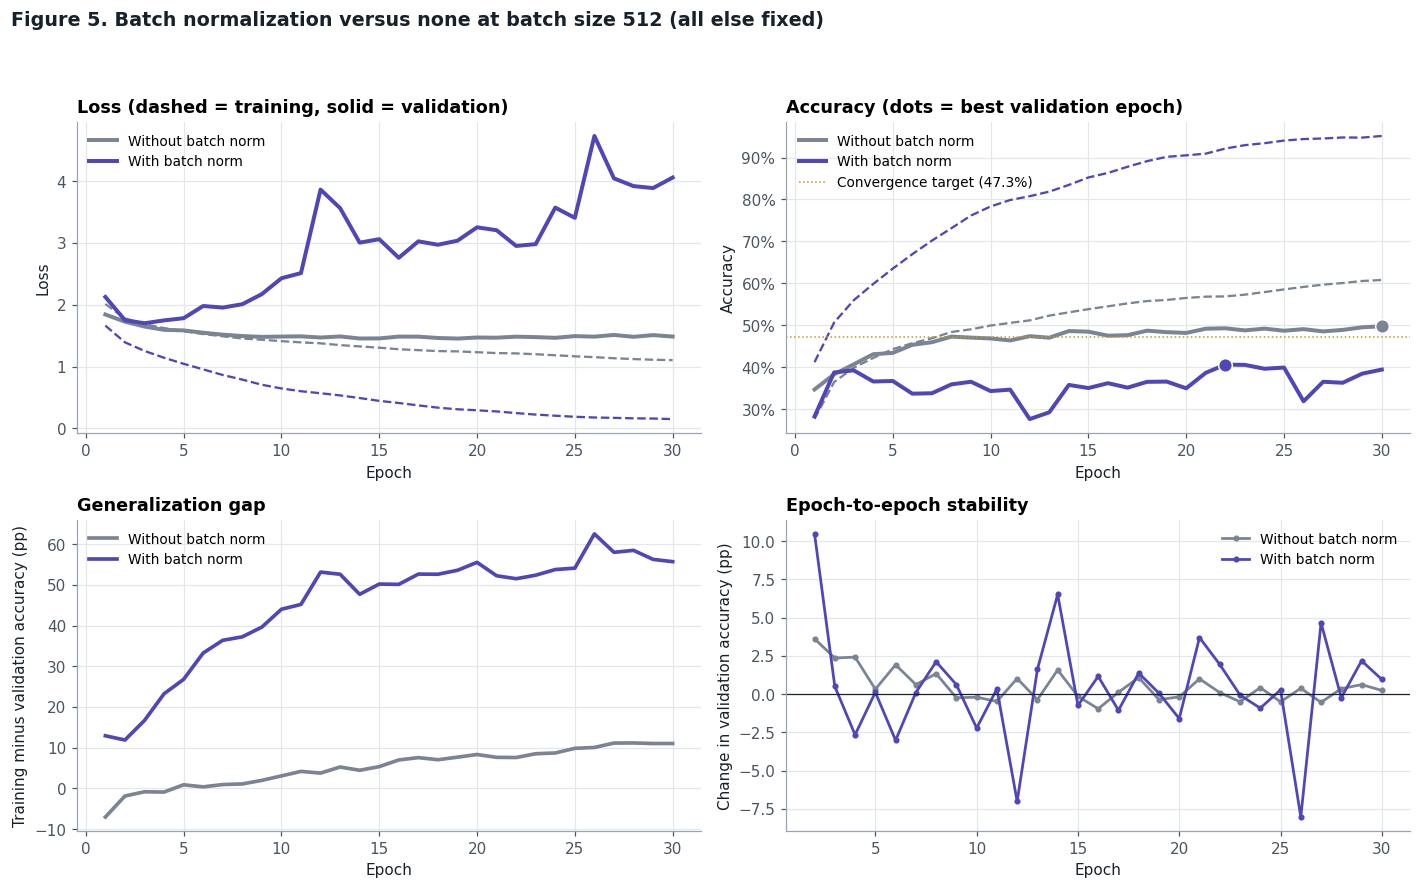

In [15]:
# Figure 5: four views of the same two runs
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))
pairs = [("Without batch norm", NOBN, PALETTE["baseline"]), ("With batch norm", bn, PALETTE["bn"])]
for label, r, c in pairs:
    hh = r["history"]; e_ = np.arange(1, r["epochs_run"] + 1)
    axes[0, 0].plot(e_, hh["loss"], color=c, lw=1.5, ls="--")
    axes[0, 0].plot(e_, hh["val_loss"], color=c, lw=2.6, label=label)
    axes[0, 1].plot(e_, hh["accuracy"], color=c, lw=1.5, ls="--")
    axes[0, 1].plot(e_, hh["val_accuracy"], color=c, lw=2.6, label=label)
    axes[0, 1].scatter(r["best_epoch"], r["best_val_acc"], s=80, color=c, edgecolor="white", zorder=5)
    axes[1, 0].plot(e_, 100 * (np.array(hh["accuracy"]) - np.array(hh["val_accuracy"])), color=c, lw=2.4, label=label)
    axes[1, 1].plot(e_[1:], 100 * np.diff(hh["val_accuracy"]), color=c, lw=1.8, marker="o", ms=3, label=label)
axes[0, 1].axhline(TARGET, color=PALETTE["final"], lw=1, ls=":", label=f"Convergence target ({TARGET:.1%})")
axes[0, 0].set(xlabel="Epoch", ylabel="Loss", title="Loss (dashed = training, solid = validation)")
axes[0, 1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy (dots = best validation epoch)")
axes[0, 1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1, 0].set(xlabel="Epoch", ylabel="Training minus validation accuracy (pp)", title="Generalization gap")
axes[1, 1].axhline(0, color=PALETTE["ink"], lw=0.8)
axes[1, 1].set(xlabel="Epoch", ylabel="Change in validation accuracy (pp)", title="Epoch-to-epoch stability")
for ax in axes.flat:
    ax.legend(loc="best", fontsize=9)
finish(fig, f"Figure 5. Batch normalization versus none at batch size {SELECTED_BS} (all else fixed)")

In [16]:
d_acc = bn["best_val_acc"] - NOBN["best_val_acc"]
_, _, p_bn = mcnemar(VAL_CORRECT[bn["name"]], VAL_CORRECT[NOBN["name"]])
e0, e1 = epochs_to(NOBN, TARGET), epochs_to(bn, TARGET)
s0, s1 = seconds_to(NOBN, e0), seconds_to(bn, e1)

acc_bn = (f"With batch normalization, best validation accuracy went from {pct(NOBN['best_val_acc'])} to {pct(bn['best_val_acc'])} "
          f"({spp(d_acc)}), {verdict(d_acc, p_bn)}.")
loss_bn = (f"The lowest validation loss was {bn['best_val_loss']:.3f} with batch normalization (epoch {bn['best_loss_epoch']}) "
           f"against {NOBN['best_val_loss']:.3f} without it (epoch {NOBN['best_loss_epoch']}).")
if e1 and e0:
    speed_bn = (f"The batch-normalized network reached {TARGET:.1%} validation accuracy (95% of the plain network's best) in epoch {e1} "
                f"({s1:.0f} s), against epoch {e0} ({s0:.0f} s) without it.")
elif e1:
    speed_bn = f"The batch-normalized network reached {TARGET:.1%} validation accuracy in epoch {e1}; the plain network never did."
else:
    speed_bn = f"The batch-normalized network never reached the {TARGET:.1%} target, while the plain network did so in epoch {e0}."
speed_bn += (f" After a single epoch, validation accuracy was {pct(bn['history']['val_accuracy'][0])} with batch normalization "
             f"and {pct(NOBN['history']['val_accuracy'][0])} without.")
j0, j1 = 100 * NOBN["jitter"], 100 * bn["jitter"]
more_stable = j1 < j0 - 0.1
stab_bn = (f"Validation-accuracy jitter after epoch 5 was {j1:.2f} pp with batch normalization and {j0:.2f} pp without, and the largest "
           f"single-epoch drops were {pp(bn['max_drop'])} and {pp(NOBN['max_drop'])}, so batch normalization made the validation curve "
           + ("smoother." if more_stable else ("noisier." if j1 > j0 + 0.1 else "about equally smooth.")))
g0, g1 = NOBN["gap_at_end"], bn["gap_at_end"]
gap_bn = (f"By epoch 30, the train–validation accuracy gap was {pp(g1)} with batch normalization and {pp(g0)} without, "
          + ("so the normalized network memorized the training set even more aggressively." if g1 > g0 + 0.01 else
             ("so batch normalization slightly reduced overfitting." if g1 < g0 - 0.01 else "so overfitting was essentially unchanged.")))
ratio = np.median(bn["epoch_times"]) / np.median(NOBN["epoch_times"])
time_bn = (f"Batch normalization changed the median epoch time by a factor of {ratio:.2f} ({np.median(bn['epoch_times']):.2f} s versus "
           f"{np.median(NOBN['epoch_times']):.2f} s), "
           + ("a modest overhead for the extra normalization work." if ratio > 1.03 else "a negligible difference."))
faster = bool(e1 and (not e0 or e1 < e0))
acc_word = ("improved" if (d_acc > NOISE_BAND or (d_acc > 0 and p_bn < 0.05)) else
            ("reduced" if (d_acc < -NOISE_BAND or (d_acc < 0 and p_bn < 0.05)) else "did not meaningfully change"))
verdict_bn = (f"Taken together, batch normalization {'sped up' if faster else 'did not speed up'} convergence, "
              f"{'made training more stable' if more_stable else 'did not make training more stable'}, and "
              f"{acc_word} the best validation accuracy.")

note(BN_ACC_SENTENCE=acc_bn, BN_LOSS_SENTENCE=loss_bn, BN_SPEED_SENTENCE=speed_bn, BN_STABILITY_SENTENCE=stab_bn,
     BN_GAP_SENTENCE=gap_bn, BN_TIME_SENTENCE=time_bn, BN_VERDICT_SENTENCE=verdict_bn)
evidence("batch normalization", ["BN_ACC_SENTENCE", "BN_LOSS_SENTENCE", "BN_SPEED_SENTENCE", "BN_STABILITY_SENTENCE",
                                 "BN_GAP_SENTENCE", "BN_TIME_SENTENCE", "BN_VERDICT_SENTENCE"])

**Evidence from this run: batch normalization**

- With batch normalization, best validation accuracy went from 49.78% to 40.64% (-9.14 pp), a difference that clears both the 1-pp noise band and a paired McNemar test (p < 0.001).
- The lowest validation loss was 1.700 with batch normalization (epoch 3) against 1.452 without it (epoch 19).
- The batch-normalized network never reached the 47.3% target, while the plain network did so in epoch 8. After a single epoch, validation accuracy was 28.30% with batch normalization and 34.72% without.
- Validation-accuracy jitter after epoch 5 was 3.04 pp with batch normalization and 0.73 pp without, and the largest single-epoch drops were 8.04 pp and 0.96 pp, so batch normalization made the validation curve noisier.
- By epoch 30, the train–validation accuracy gap was 55.68 pp with batch normalization and 11.04 pp without, so the normalized network memorized the training set even more aggressively.
- Batch normalization changed the median epoch time by a factor of 1.17 (0.76 s versus 0.65 s), a modest overhead for the extra normalization work.
- Taken together, batch normalization did not speed up convergence, did not make training more stable, and reduced the best validation accuracy.

### Did batch normalization help?

**Validation performance.** {{BN_ACC_SENTENCE}} {{BN_LOSS_SENTENCE}}

**Convergence speed.** {{BN_SPEED_SENTENCE}} Normalizing each layer's pre-activations keeps their scale steady while earlier layers change, so later layers are not chasing a moving target. Ioffe and Szegedy (2015) framed this as reducing internal covariate shift; Santurkar et al. (2018) later showed that the larger effect is a smoother loss landscape with more predictable gradients, which is what lets the optimizer make faster early progress.

**Training stability.** {{BN_STABILITY_SENTENCE}} One subtlety matters when reading these curves. During training, batch normalization uses the statistics of the current mini-batch, but at validation time it uses running averages accumulated over training. When those averages lag behind rapidly changing weights, the validation curve can wobble even while the training loss is smooth.

**Generalization.** {{BN_GAP_SENTENCE}} The noise in batch statistics gives batch normalization a mild regularizing effect, but that effect is small next to dropout, and on its own it does not stop a large fully connected network from memorizing the training set.

**Cost.** {{BN_TIME_SENTENCE}}

**Verdict.** {{BN_VERDICT_SENTENCE}} Because the search space in Steps 5 and 6 is defined for a batch-normalized network, this run is also the natural reference point for those searches.

#### Optional extension: does batch normalization tolerate a higher learning rate?

A common claim is that batch normalization lets a network train safely at larger learning rates (Ioffe & Szegedy, 2015). Testing it changes a second variable, so I keep it separate from the controlled comparison above: both models are retrained at a learning rate of 0.005 (five times Adam's default) with everything else unchanged.

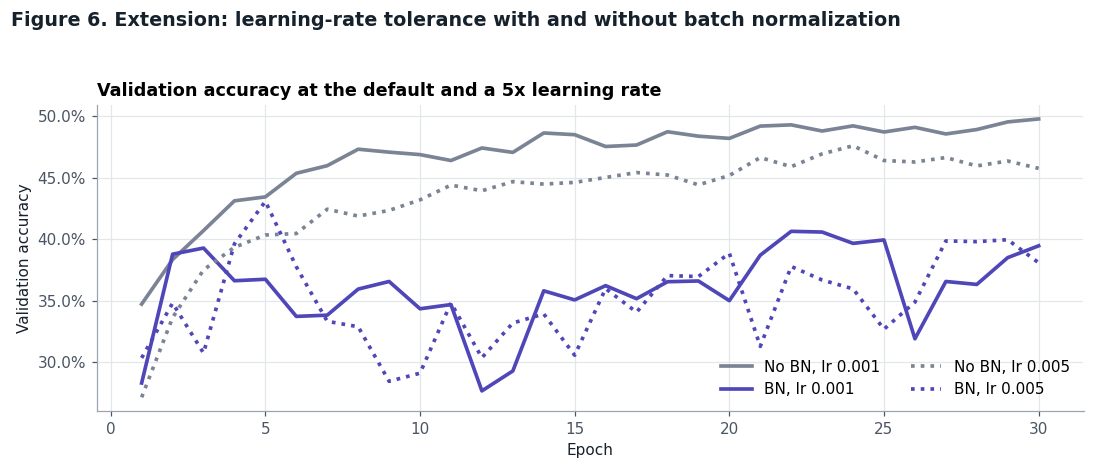

**Evidence from this run: learning-rate extension**

- At a learning rate of 0.005, the plain network's best validation accuracy was 47.60% (status: ok, jitter ±0.76 pp) and the batch-normalized network's was 43.08% (status: unstable, jitter ±3.64 pp), changes of -2.18 pp and +2.44 pp relative to the default learning rate. This fits the claim: moving to the larger step size was far worse for the plain network than for the normalized one.

In [17]:
if RUN_LR_EXTENSION:
    ext_plain = train_run(f"nobn_lr005_bs{SELECTED_BS}", make_config(batch_size=SELECTED_BS, learning_rate=0.005), group="Step 4 extension")
    ext_bn = train_run(f"bn_lr005_bs{SELECTED_BS}", make_config(batch_norm=True, batch_size=SELECTED_BS, learning_rate=0.005), group="Step 4 extension")
    fig, ax = plt.subplots(figsize=(10, 4.3))
    for r, c, ls, lab in [(NOBN, PALETTE["baseline"], "-", "No BN, lr 0.001"), (bn, PALETTE["bn"], "-", "BN, lr 0.001"),
                          (ext_plain, PALETTE["baseline"], ":", "No BN, lr 0.005"), (ext_bn, PALETTE["bn"], ":", "BN, lr 0.005")]:
        ax.plot(np.arange(1, r["epochs_run"] + 1), r["history"]["val_accuracy"], color=c, ls=ls, lw=2.4, label=lab)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set(xlabel="Epoch", ylabel="Validation accuracy", title="Validation accuracy at the default and a 5x learning rate")
    ax.legend(ncol=2)
    finish(fig, "Figure 6. Extension: learning-rate tolerance with and without batch normalization")
    drop_plain = NOBN["best_val_acc"] - ext_plain["best_val_acc"]
    drop_bn = bn["best_val_acc"] - ext_bn["best_val_acc"]
    ext_s = (f"At a learning rate of 0.005, the plain network's best validation accuracy was {pct(ext_plain['best_val_acc'])} "
             f"(status: {ext_plain['status']}, jitter ±{100 * ext_plain['jitter']:.2f} pp) and the batch-normalized network's was "
             f"{pct(ext_bn['best_val_acc'])} (status: {ext_bn['status']}, jitter ±{100 * ext_bn['jitter']:.2f} pp), "
             f"changes of {spp(-drop_plain)} and {spp(-drop_bn)} relative to the default learning rate. "
             + ("This fits the claim: moving to the larger step size was far worse for the plain network than for the normalized one."
                if drop_plain > drop_bn + NOISE_BAND else
                ("Here the normalized network was hurt more, which does not support the claim at this setting."
                 if drop_bn > drop_plain + NOISE_BAND else
                 "The two networks responded similarly, so this single run neither supports nor contradicts the claim.")))
else:
    ext_s = "The optional higher-learning-rate extension was switched off for this run."
note(EXT_SENTENCE=ext_s)
evidence("learning-rate extension", ["EXT_SENTENCE"])

{{EXT_SENTENCE}} I keep this result out of the main batch-normalization verdict because it changes two things at once, but it is useful context for the search: the learning-rate range in Steps 5 and 6 includes 0.005, and this run shows what that end of the range looks like.

## Step 5: Conduct random search

The search uses a batch-normalized dense network (Dense → BatchNorm → ReLU → Dropout in every hidden block, with the same width in every hidden layer) over the space given in the brief:

| Hyperparameter | Values | Why the range is sensible |
|---|---|---|
| Learning rate | 0.0001, 0.0005, 0.001, 0.005 | Roughly log-spaced around Adam's default, from cautious to aggressive |
| Batch size | 32, 64, 128, 256 | Covers the noisy-but-slow to smooth-but-fast regimes seen in Step 3 |
| Hidden layers | 2, 3, 4 | Depth on either side of the baseline's three layers |
| Hidden units per layer | 128, 256, 512 | From a quarter of to the full width of the baseline's first layer |
| Dropout rate | 0.0, 0.2, 0.4 | From no regularization to fairly strong regularization |

**I kept the ranges unchanged.** They already bracket sensible values for this model, and keeping them identical is what makes the Step 6 comparison fair. The full grid has 4 × 4 × 3 × 3 × 3 = 432 combinations, so eight trials cover under 2% of it. That sounds hopeless, but it is exactly where random search does well: if only a few hyperparameters really matter, random sampling tries each of them at many distinct values instead of wasting trials on unimportant ones (Bergstra & Bengio, 2012). A quick calculation sets expectations: the chance that at least one of eight random trials lands in the top 10% of the space is 1 − 0.9⁸ ≈ 57%, and for the top 5% it is 1 − 0.95⁸ ≈ 34%.

**Shared trial protocol for Steps 5 and 6.** Every trial uses the same seed, a cap of 30 epochs and early stopping on validation accuracy with a patience of 8 epochs. The score is the best validation accuracy reached, and the weights from that epoch are kept. A trial is labelled *failed* if training produced NaN losses or never beat 20% validation accuracy (twice chance), and *unstable* if its validation accuracy swung by more than 2 pp per epoch on average after epoch 5, or fell by 5 pp or more in a single epoch. The test set is never used here.

In [18]:
SEARCH_SPACE = {
    "learning_rate": [0.0001, 0.0005, 0.001, 0.005],
    "batch_size": [32, 64, 128, 256],
    "layers": [2, 3, 4],
    "units": [128, 256, 512],
    "dropout": [0.0, 0.2, 0.4],
}

def search_config(hp):
    return make_config(hidden=(hp["units"],) * hp["layers"], batch_norm=True, dropout=hp["dropout"],
                       learning_rate=hp["learning_rate"], batch_size=hp["batch_size"])

def train_trial(hp, method, number, phase):
    step = "5" if method == "random" else "6"
    rec = train_run(f"{method}_t{number}", search_config(hp), group=f"Step {step}: {method} search", early_stopping=True)
    rec.update(hp=dict(hp), method=method, trial=number, phase=phase)
    print(f"{method:>6} #{number} ({phase}): lr={hp['learning_rate']:g}, bs={hp['batch_size']}, "
          f"{hp['layers']}x{hp['units']}, dropout={hp['dropout']:g} -> {pct(rec['best_val_acc'])} "
          f"(epoch {rec['best_epoch']}/{rec['epochs_run']}, {rec['status']}, {rec['total_time']:.0f}s)")
    return rec

grid = list(itertools.product(*SEARCH_SPACE.values()))
search_rng = np.random.default_rng(SEED)
picks = search_rng.choice(len(grid), size=N_TRIALS, replace=False)   # eight distinct configurations
RANDOM_TRIALS = [train_trial(dict(zip(SEARCH_SPACE, grid[int(g)])), "random", n, "random") for n, g in enumerate(picks, start=1)]

random #1 (random): lr=0.005, bs=256, 4x512, dropout=0.2 -> 46.74% (epoch 26/30, unstable, 44s)
random #2 (random): lr=0.001, bs=256, 2x256, dropout=0.2 -> 45.60% (epoch 7/15, ok, 19s)
random #3 (random): lr=0.005, bs=64, 4x128, dropout=0 -> 44.92% (epoch 3/11, ok, 55s)
random #4 (random): lr=0.001, bs=128, 3x128, dropout=0 -> 40.76% (epoch 5/13, unstable, 30s)
random #5 (random): lr=0.0005, bs=128, 4x256, dropout=0.4 -> 49.04% (epoch 13/21, ok, 60s)
random #6 (random): lr=0.0005, bs=128, 4x512, dropout=0.2 -> 46.26% (epoch 6/14, unstable, 40s)
random #7 (random): lr=0.0001, bs=64, 3x128, dropout=0.2 -> 50.40% (epoch 27/30, ok, 135s)
random #8 (random): lr=0.005, bs=32, 2x256, dropout=0.4 -> 51.06% (epoch 23/30, unstable, 216s)


**Table 1. Random search: eight trials under the shared protocol**

,Learning rate,Batch size,Layers,Hidden units,Dropout,Best validation accuracy,Key observation,Best epoch,Epochs run,Status,Time (s)
Trial,,,,,,,,,,,
1,0.005,256,4,512,0.2,46.74%,Noisy validation curve (±3.4 pp per epoch); la...,26,30,unstable,44
2,0.001,256,2,256,0.2,45.60%,Steady training with a moderate train–val gap,7,15,ok,19
3,0.005,64,4,128,0,44.92%,Peaked early (epoch 3),3,11,ok,55
4,0.001,128,3,128,0,40.76%,Peaked early (epoch 5); noisy validation curve...,5,13,unstable,30
5,0.0005,128,4,256,0.4,49.04%,"Small train–val gap, capacity-limited",13,21,ok,60
6,0.0005,128,4,512,0.2,46.26%,Noisy validation curve (±4.6 pp per epoch),6,14,unstable,40
7,0.0001,64,3,128,0.2,50.40%,Steady training with a moderate train–val gap,27,30,ok,135
8,0.005,32,2,256,0.4,51.06%,Best in this search; noisy validation curve (±...,23,30,unstable,216


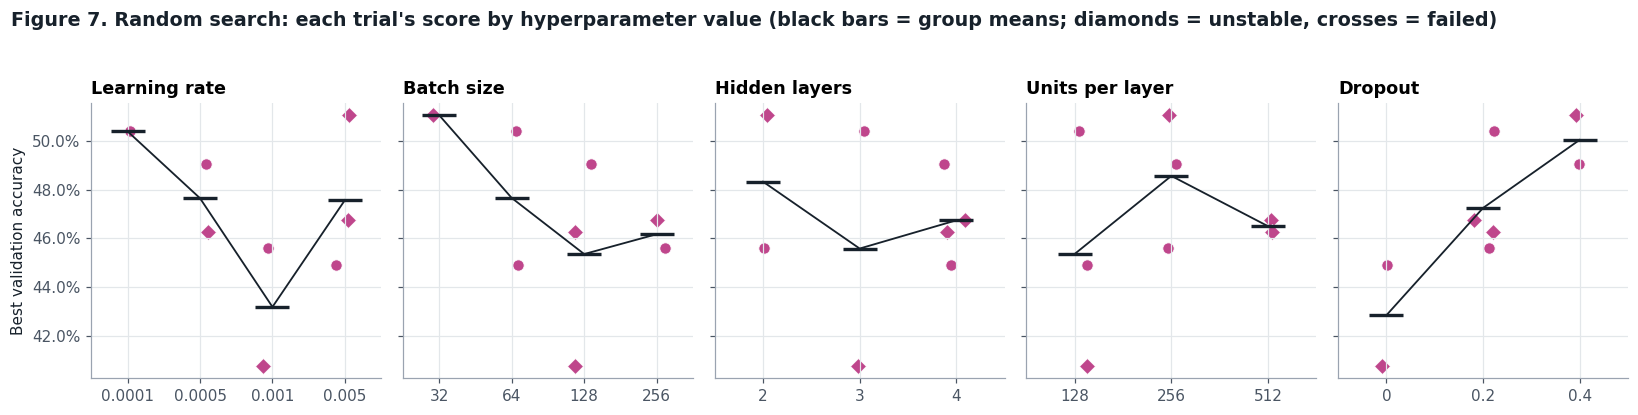

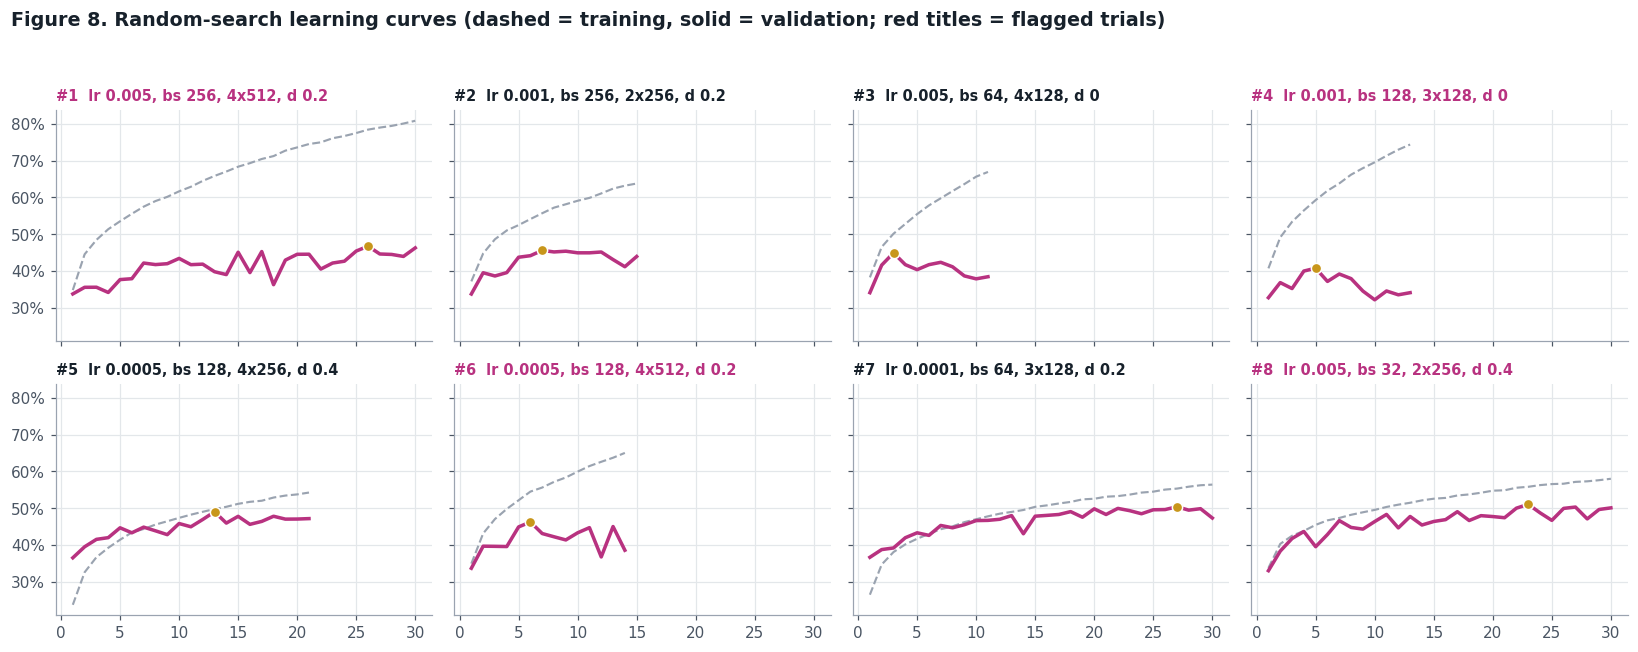

In [19]:
def trial_table(trials, extra_phase=False):
    best_name = max(trials, key=lambda r: r["best_val_acc"])["name"]
    rows = []
    for r in trials:
        hp = r["hp"]
        row = {"Trial": r["trial"], "Learning rate": f"{hp['learning_rate']:g}", "Batch size": hp["batch_size"],
               "Layers": hp["layers"], "Hidden units": hp["units"], "Dropout": f"{hp['dropout']:g}",
               "Best validation accuracy": pct(r["best_val_acc"]), "Key observation": observe(r, best_name),
               "Best epoch": r["best_epoch"], "Epochs run": r["epochs_run"], "Status": r["status"],
               "Time (s)": round(r["total_time"])}
        if extra_phase:
            row["Phase"] = r["phase"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("Trial")

show_table(trial_table(RANDOM_TRIALS), "Table 1. Random search: eight trials under the shared protocol")

def plot_effects(trials, title, by_method=False):
    fig, axes = plt.subplots(1, len(SEARCH_SPACE), figsize=(15, 3.8), sharey=True)
    jit = np.random.default_rng(0)
    for ax, (hp, values) in zip(axes, SEARCH_SPACE.items()):
        for r in trials:
            xpos = values.index(r["hp"][hp]) + jit.uniform(-0.13, 0.13)
            marker = {"failed": "X", "unstable": "D"}.get(r["status"], "o")
            ax.scatter(xpos, r["best_val_acc"], s=55, marker=marker, alpha=0.9, edgecolor="white", linewidth=0.6,
                       color=PALETTE[r["method"]] if by_method else PALETTE["random"])
        means = [np.mean([r["best_val_acc"] for r in trials if r["hp"][hp] == v]) if any(r["hp"][hp] == v for r in trials) else np.nan
                 for v in values]
        ax.plot(range(len(values)), means, color=PALETTE["ink"], lw=1.2, marker="_", ms=22, mew=2.2)
        ax.set_xticks(range(len(values)), [f"{v:g}" for v in values])
        ax.set_xlim(-0.5, len(values) - 0.5); ax.set_title(HP_LABELS[hp])
    axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[0].set_ylabel("Best validation accuracy")
    finish(fig, title)

plot_effects(RANDOM_TRIALS, "Figure 7. Random search: each trial's score by hyperparameter value "
             "(black bars = group means; diamonds = unstable, crosses = failed)")

def plot_trial_curves(trials, title, color):
    cols = 4; rows_ = math.ceil(len(trials) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(15, 3.0 * rows_), sharex=True, sharey=True)
    for ax, r in zip(axes.flat, trials):
        e_ = np.arange(1, r["epochs_run"] + 1)
        ax.plot(e_, r["history"]["accuracy"], color=PALETTE["train"], lw=1.4, ls="--")
        ax.plot(e_, r["history"]["val_accuracy"], color=color, lw=2.3)
        ax.scatter(r["best_epoch"], r["best_val_acc"], s=45, color=PALETTE["final"], edgecolor="white", zorder=5)
        hp = r["hp"]
        ax.set_title(f"#{r['trial']}  lr {hp['learning_rate']:g}, bs {hp['batch_size']}, {hp['layers']}x{hp['units']}, d {hp['dropout']:g}",
                     fontsize=9.5, color=PALETTE["alert"] if r["status"] != "ok" else PALETTE["ink"])
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    for ax in list(axes.flat)[len(trials):]:
        ax.axis("off")
    finish(fig, title)

plot_trial_curves(RANDOM_TRIALS, "Figure 8. Random-search learning curves (dashed = training, solid = validation; red titles = flagged trials)",
                  PALETTE["random"])

In [20]:
def marginal_ranges(trials):
    df = pd.DataFrame([{**r["hp"], "acc": r["best_val_acc"]} for r in trials])
    out = {}
    for hp in SEARCH_SPACE:
        g = df.groupby(hp)["acc"].mean()
        if len(g) > 1:
            out[hp] = (g.max() - g.min(), g.idxmax(), g.idxmin(), len(g))
    return dict(sorted(out.items(), key=lambda kv: -kv[1][0]))

def flagged_sentence(trials, label):
    bad = [r for r in trials if r["status"] != "ok"]
    if not bad:
        noisiest = max(trials, key=lambda r: r["jitter"])
        return (f"No {label} trial failed or met the instability criteria, although trial {noisiest['trial']} "
                f"(learning rate {noisiest['hp']['learning_rate']:g}, batch size {noisiest['hp']['batch_size']}) "
                f"had the noisiest validation curve (±{100 * noisiest['jitter']:.2f} pp per epoch).")
    parts = [f"trial {r['trial']} ({r['status']}; learning rate {r['hp']['learning_rate']:g}, batch size {r['hp']['batch_size']}, "
             f"dropout {r['hp']['dropout']:g}, best {pct(r['best_val_acc'])})" for r in bad]
    return f"Of the {len(trials)} {label} trials, {len(bad)} {'was' if len(bad) == 1 else 'were'} flagged: " + "; ".join(parts) + "."

rs_best = max(RANDOM_TRIALS, key=lambda r: r["best_val_acc"])
rs_worst = min(RANDOM_TRIALS, key=lambda r: r["best_val_acc"])
accs = np.array([r["best_val_acc"] for r in RANDOM_TRIALS])
rs_ranges = marginal_ranges(RANDOM_TRIALS)
names = list(rs_ranges)
effect_s = (f"Grouping the trials by each hyperparameter, the spread in mean best validation accuracy was largest for "
            f"{HP_LABELS[names[0]].lower()} ({pp(rs_ranges[names[0]][0])} between its best value, {rs_ranges[names[0]][1]:g}, "
            f"and its worst, {rs_ranges[names[0]][2]:g})"
            + (f", followed by {HP_LABELS[names[1]].lower()} ({pp(rs_ranges[names[1]][0])})" if len(names) > 1 else "")
            + (f" and {HP_LABELS[names[2]].lower()} ({pp(rs_ranges[names[2]][0])})" if len(names) > 2 else "")
            + (f"; {HP_LABELS[names[-1]].lower()} mattered least ({pp(rs_ranges[names[-1]][0])})." if len(names) > 3 else "."))
note(RS_BEST_SENTENCE=(f"The best random-search configuration was trial {rs_best['trial']}: {describe(rs_best['config'])}, "
                       f"which reached {pct(rs_best['best_val_acc'])} validation accuracy at epoch {rs_best['best_epoch']}."),
     RS_SPREAD_SENTENCE=(f"Across the eight trials, best validation accuracy ranged from {pct(accs.min())} to {pct(accs.max())} "
                         f"(median {pct(np.median(accs))}), and {int(np.sum(accs > bn['best_val_acc']))} of the eight beat the "
                         f"Step 4 batch-normalized reference of {pct(bn['best_val_acc'])}."),
     RS_EFFECT_SENTENCE=effect_s,
     RS_UNSTABLE_SENTENCE=flagged_sentence(RANDOM_TRIALS, "random-search"),
     RS_WEAK_SENTENCE=(f"The weakest trial (#{rs_worst['trial']}: {describe(rs_worst['config'])}) reached only "
                       f"{pct(rs_worst['best_val_acc'])}; its key observation was: {observe(rs_worst).lower()}."))
evidence("random search", ["RS_BEST_SENTENCE", "RS_SPREAD_SENTENCE", "RS_EFFECT_SENTENCE", "RS_UNSTABLE_SENTENCE", "RS_WEAK_SENTENCE"])

**Evidence from this run: random search**

- The best random-search configuration was trial 8: 2 hidden layers of 256 units, with batch normalization, dropout 0.4, learning rate 0.005 and batch size 32, which reached 51.06% validation accuracy at epoch 23.
- Across the eight trials, best validation accuracy ranged from 40.76% to 51.06% (median 46.50%), and 8 of the eight beat the Step 4 batch-normalized reference of 40.64%.
- Grouping the trials by each hyperparameter, the spread in mean best validation accuracy was largest for learning rate (7.22 pp between its best value, 0.0001, and its worst, 0.001), followed by dropout (7.21 pp) and batch size (5.71 pp); hidden layers mattered least (2.75 pp).
- Of the 8 random-search trials, 4 were flagged: trial 1 (unstable; learning rate 0.005, batch size 256, dropout 0.2, best 46.74%); trial 4 (unstable; learning rate 0.001, batch size 128, dropout 0, best 40.76%); trial 6 (unstable; learning rate 0.0005, batch size 128, dropout 0.2, best 46.26%); trial 8 (unstable; learning rate 0.005, batch size 32, dropout 0.4, best 51.06%).
- The weakest trial (#4: 3 hidden layers of 128 units, with batch normalization, dropout 0, learning rate 0.001 and batch size 128) reached only 40.76%; its key observation was: peaked early (epoch 5); noisy validation curve (±2.2 pp per epoch); large train–val gap (19 pp).

### What random search revealed

**Best configuration.** {{RS_BEST_SENTENCE}} {{RS_SPREAD_SENTENCE}}

**Which hyperparameters mattered most.** {{RS_EFFECT_SENTENCE}} I treat this ranking as a hint, not a finding. With eight trials, each value of a hyperparameter appears only once or twice, and the values are confounded with each other: a learning rate can look bad simply because it happened to be paired with heavy dropout or a narrow network. The learning rate is usually the single most important hyperparameter for neural networks (Goodfellow et al., 2016, Chapter 11), so if it does not top the list here, the small sample is the more likely explanation than a genuinely flat response.

**Unstable or ineffective configurations.** {{RS_UNSTABLE_SENTENCE}} {{RS_WEAK_SENTENCE}} In this space, the usual causes of instability are the largest learning rate (0.005) combined with small batches, where each noisy step is also a large one. The usual causes of weak but stable runs are very small learning rates (the network simply has not converged within 30 epochs) and narrow networks with heavy dropout, which leave too little effective capacity.

## Step 6: Conduct Bayesian optimization

I use Optuna's Tree-structured Parzen Estimator (TPE), a sequential model-based form of Bayesian optimization (Akiba et al., 2019; Bergstra et al., 2011). Instead of fitting a single surrogate of accuracy as a function of the hyperparameters, TPE splits completed trials into a "good" group and a "rest" group, models the density of hyperparameter values in each, and proposes the next configuration where the ratio of good to rest is highest (Watanabe, 2023). Gaussian-process Bayesian optimization (Snoek et al., 2012) follows the same propose, evaluate and update loop with a different surrogate model.

Two configuration choices matter more than they look with only eight trials:

- **Random warm-up.** Optuna's TPE sampler uses random sampling for its first 10 trials by default (Optuna Contributors, n.d.), and KerasTuner's Bayesian tuner defaults to three random points per hyperparameter, which would be 15 here (Keras Team, n.d.). Either default exceeds the eight-trial budget and would turn the "Bayesian" search into a second random search. I set the warm-up to 3 trials, so 5 of the 8 trials are model-guided.
- **Ordered values.** Every hyperparameter here is ordinal (0.0005 really does sit between 0.0001 and 0.001). Declaring them as unordered categories would throw that information away, so I let TPE choose an *index* into each value list with `suggest_int`. The model can then learn that "smaller is better" for a hyperparameter, while every proposal is still one of the exact values used in Step 5.

Everything else (seed, epoch cap, early stopping, score, failure and instability rules) is identical to the random search.

In [21]:
BAYES_TRIALS = []

def objective(trial):
    hp = {k: v[trial.suggest_int(f"{k}_idx", 0, len(v) - 1)] for k, v in SEARCH_SPACE.items()}
    phase = "random warm-up" if trial.number < TPE_STARTUP_TRIALS else "TPE-guided"
    rec = train_trial(hp, "bayes", trial.number + 1, phase)
    BAYES_TRIALS.append(rec)
    for key in ("best_epoch", "status", "epochs_run"):
        trial.set_user_attr(key, rec[key])
    return rec["best_val_acc"]

sampler = optuna.samplers.TPESampler(seed=SEED, n_startup_trials=TPE_STARTUP_TRIALS, multivariate=True)
study = optuna.create_study(direction="maximize", sampler=sampler, study_name="cifar10_dense_tpe")
study.optimize(objective, n_trials=N_TRIALS)
show_table(trial_table(BAYES_TRIALS, extra_phase=True), "Table 1b. Bayesian optimization (TPE): eight trials under the shared protocol")

 bayes #1 (random warm-up): lr=0.0005, bs=256, 4x256, dropout=0 -> 41.04% (epoch 4/12, ok, 19s)
 bayes #2 (random warm-up): lr=0.0001, bs=32, 4x256, dropout=0.4 -> 53.14% (epoch 27/30, ok, 300s)
 bayes #3 (random warm-up): lr=0.0001, bs=256, 4x128, dropout=0 -> 45.32% (epoch 9/17, ok, 26s)
 bayes #4 (TPE-guided): lr=0.0001, bs=32, 4x128, dropout=0.4 -> 48.50% (epoch 28/30, ok, 297s)
 bayes #5 (TPE-guided): lr=0.005, bs=32, 3x512, dropout=0.4 -> 51.24% (epoch 28/30, ok, 260s)
 bayes #6 (TPE-guided): lr=0.0005, bs=32, 2x256, dropout=0 -> 42.78% (epoch 6/14, ok, 97s)
 bayes #7 (TPE-guided): lr=0.0001, bs=128, 4x256, dropout=0.4 -> 49.42% (epoch 21/29, ok, 79s)
 bayes #8 (TPE-guided): lr=0.005, bs=128, 3x128, dropout=0.2 -> 48.28% (epoch 20/28, ok, 66s)


**Table 1b. Bayesian optimization (TPE): eight trials under the shared protocol**

,Learning rate,Batch size,Layers,Hidden units,Dropout,Best validation accuracy,Key observation,Best epoch,Epochs run,Status,Time (s),Phase
Trial,,,,,,,,,,,,
1,0.0005,256,4,256,0,41.04%,Peaked early (epoch 4); large train–val gap (1...,4,12,ok,19,random warm-up
2,0.0001,32,4,256,0.4,53.14%,"Best in this search; small train–val gap, capa...",27,30,ok,300,random warm-up
3,0.0001,256,4,128,0,45.32%,Steady training with a moderate train–val gap,9,17,ok,26,random warm-up
4,0.0001,32,4,128,0.4,48.50%,"Small train–val gap, capacity-limited",28,30,ok,297,TPE-guided
5,0.005,32,3,512,0.4,51.24%,Steady training with a moderate train–val gap,28,30,ok,260,TPE-guided
6,0.0005,32,2,256,0,42.78%,Large train–val gap (21 pp),6,14,ok,97,TPE-guided
7,0.0001,128,4,256,0.4,49.42%,"Small train–val gap, capacity-limited",21,29,ok,79,TPE-guided
8,0.005,128,3,128,0.2,48.28%,Steady training with a moderate train–val gap,20,28,ok,66,TPE-guided


**Search-method comparison under the same eight-trial budget**

,Best val accuracy,Best trial,First trial within 1 pp of overall best,Median val accuracy,Std across trials (pp),Failed,Unstable,Total epochs trained,Total time (min),Mean batch size
Method,,,,,,,,,,
Random search,51.06%,8,never,46.50%,3.34,0,4,164,10.0,132
Bayesian optimization (TPE),53.14%,2,2,48.39%,4.14,0,0,190,19.1,112


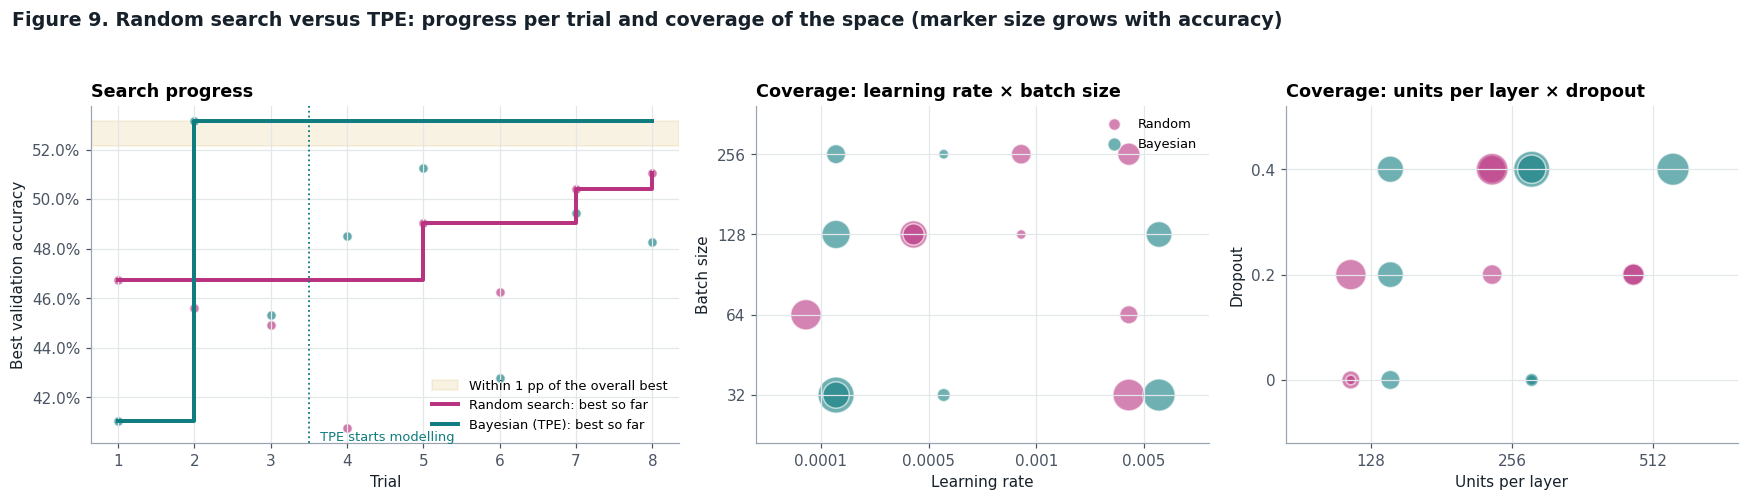

In [22]:
ALL_TRIALS = RANDOM_TRIALS + BAYES_TRIALS
overall_best = max(r["best_val_acc"] for r in ALL_TRIALS)
STRONG = overall_best - NOISE_BAND

def first_strong(trials):
    return next((r["trial"] for r in trials if r["best_val_acc"] >= STRONG), None)

def search_summary(trials, label):
    a = np.array([r["best_val_acc"] for r in trials])
    b = max(trials, key=lambda r: r["best_val_acc"])
    return {"Method": label, "Best val accuracy": a.max(), "Best trial": b["trial"],
            "First trial within 1 pp of overall best": first_strong(trials) or "never",
            "Median val accuracy": float(np.median(a)), "Std across trials (pp)": 100 * a.std(ddof=1),
            "Failed": sum(r["status"] == "failed" for r in trials), "Unstable": sum(r["status"] == "unstable" for r in trials),
            "Total epochs trained": sum(r["epochs_run"] for r in trials),
            "Total time (min)": sum(r["total_time"] for r in trials) / 60,
            "Mean batch size": np.mean([r["hp"]["batch_size"] for r in trials])}

cmp = pd.DataFrame([search_summary(RANDOM_TRIALS, "Random search"), search_summary(BAYES_TRIALS, "Bayesian optimization (TPE)")]).set_index("Method")
show_table(cmp, "Search-method comparison under the same eight-trial budget",
           {"Best val accuracy": "{:.2%}", "Median val accuracy": "{:.2%}", "Std across trials (pp)": "{:.2f}",
            "Total time (min)": "{:.1f}", "Mean batch size": "{:.0f}"})

# Figure 9: how each search progressed and where it looked
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
ax.axhspan(STRONG, overall_best, color=PALETTE["final"], alpha=0.12, label="Within 1 pp of the overall best")
for trials, key, lab in [(RANDOM_TRIALS, "random", "Random search"), (BAYES_TRIALS, "bayes", "Bayesian (TPE)")]:
    tn = [r["trial"] for r in trials]; sc = [r["best_val_acc"] for r in trials]
    ax.plot(tn, np.maximum.accumulate(sc), color=PALETTE[key], lw=2.6, drawstyle="steps-post", label=f"{lab}: best so far")
    ax.scatter(tn, sc, color=PALETTE[key], s=40, alpha=0.65, edgecolor="white")
ax.axvline(TPE_STARTUP_TRIALS + 0.5, color=PALETTE["bayes"], ls=":", lw=1.2)
ax.text(TPE_STARTUP_TRIALS + 0.6, ax.get_ylim()[0], " TPE starts modelling", color=PALETTE["bayes"], fontsize=8.5, va="bottom")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(xlabel="Trial", ylabel="Best validation accuracy", title="Search progress")
ax.legend(loc="lower right", fontsize=8.5)

def coverage(ax, xk, yk):
    for trials, key, off in [(RANDOM_TRIALS, "random", -0.14), (BAYES_TRIALS, "bayes", 0.14)]:
        xs = [SEARCH_SPACE[xk].index(r["hp"][xk]) + off for r in trials]
        ys = [SEARCH_SPACE[yk].index(r["hp"][yk]) for r in trials]
        lo_a = min(q["best_val_acc"] for q in ALL_TRIALS); hi_a = max(q["best_val_acc"] for q in ALL_TRIALS)
        sizes = [40 + 520 * ((r["best_val_acc"] - lo_a) / max(hi_a - lo_a, 1e-9)) ** 1.5 for r in trials]
        ax.scatter(xs, ys, s=sizes, color=PALETTE[key], alpha=0.6, edgecolor="white", label="Random" if key == "random" else "Bayesian")
    ax.set_xticks(range(len(SEARCH_SPACE[xk])), [f"{v:g}" for v in SEARCH_SPACE[xk]])
    ax.set_yticks(range(len(SEARCH_SPACE[yk])), [f"{v:g}" for v in SEARCH_SPACE[yk]])
    ax.set_xlim(-0.6, len(SEARCH_SPACE[xk]) - 0.4); ax.set_ylim(-0.6, len(SEARCH_SPACE[yk]) - 0.4)
    ax.set(xlabel=HP_LABELS[xk], ylabel=HP_LABELS[yk], title=f"Coverage: {HP_LABELS[xk].lower()} × {HP_LABELS[yk].lower()}")
coverage(axes[1], "learning_rate", "batch_size")
coverage(axes[2], "units", "dropout")
axes[1].legend(loc="upper right", fontsize=8.5, markerscale=0.5)
finish(fig, "Figure 9. Random search versus TPE: progress per trial and coverage of the space (marker size grows with accuracy)")

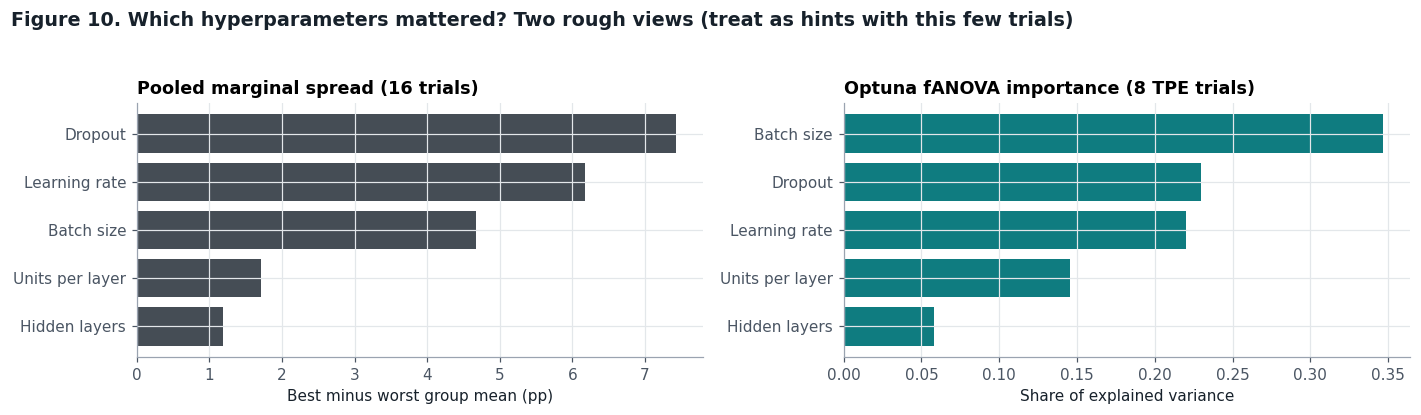

In [23]:
# Figure 10: pooled marginal effects over all sixteen trials, and Optuna's fANOVA importance
pooled = marginal_ranges(ALL_TRIALS)
try:
    imp = {k.replace("_idx", ""): v for k, v in optuna.importance.get_param_importances(study).items()}
except Exception as err:          # needs enough completed trials; not fatal
    imp = {}
    print("Optuna importance unavailable:", err)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
keys = list(pooled)[::-1]
ax1.barh([HP_LABELS[k] for k in keys], [100 * pooled[k][0] for k in keys], color=PALETTE["ink"], alpha=0.8)
ax1.set(xlabel="Best minus worst group mean (pp)", title="Pooled marginal spread (16 trials)")
if imp:
    ik = sorted(imp, key=imp.get)
    ax2.barh([HP_LABELS.get(k, k) for k in ik], [imp[k] for k in ik], color=PALETTE["bayes"])
    ax2.set(xlabel="Share of explained variance", title="Optuna fANOVA importance (8 TPE trials)")
else:
    ax2.axis("off")
finish(fig, "Figure 10. Which hyperparameters mattered? Two rough views (treat as hints with this few trials)")

In [24]:
bo_best = max(BAYES_TRIALS, key=lambda r: r["best_val_acc"])
warm = [r for r in BAYES_TRIALS if r["phase"] == "random warm-up"]
guided = [r for r in BAYES_TRIALS if r["phase"] == "TPE-guided"]
mw, mg = np.mean([r["best_val_acc"] for r in warm]), np.mean([r["best_val_acc"] for r in guided])
beat_warm = sum(r["best_val_acc"] > max(w["best_val_acc"] for w in warm) for r in guided)
seen = [tuple(r["hp"].values()) for r in BAYES_TRIALS]
dups = len(seen) - len(set(seen))
_, _, p_search = mcnemar(VAL_CORRECT[bo_best["name"]], VAL_CORRECT[rs_best["name"]])
d_search = bo_best["best_val_acc"] - rs_best["best_val_acc"]
fs_r, fs_b = first_strong(RANDOM_TRIALS), first_strong(BAYES_TRIALS)
sd_r, sd_b = cmp.loc["Random search", "Std across trials (pp)"], cmp.loc["Bayesian optimization (TPE)", "Std across trials (pp)"]
fr, ur = cmp.loc["Random search", ["Failed", "Unstable"]]
fb, ub = cmp.loc["Bayesian optimization (TPE)", ["Failed", "Unstable"]]
tr, tb = cmp.loc["Random search", "Total time (min)"], cmp.loc["Bayesian optimization (TPE)", "Total time (min)"]
er, eb = cmp.loc["Random search", "Total epochs trained"], cmp.loc["Bayesian optimization (TPE)", "Total epochs trained"]
mbr, mbb = cmp.loc["Random search", "Mean batch size"], cmp.loc["Bayesian optimization (TPE)", "Mean batch size"]

if abs(d_search) <= NOISE_BAND and p_search >= 0.05:
    verdict_search = (f"Under an equal eight-trial budget the two methods finished in a statistical tie: their best configurations differ by "
                      f"{pp(abs(d_search))}, inside the noise band, and the paired test agrees ({fmt_p(p_search)}).")
else:
    winner = "Bayesian optimization" if d_search > 0 else "Random search"
    verdict_search = (f"{winner} found the stronger configuration under the same budget ({pp(abs(d_search))} ahead, {fmt_p(p_search)}), "
                      f"although a single seed per trial means this ranking could still shift on a rerun.")
def reach(method, x): return f"{method} first got there in trial {x}" if x else f"{method} never got there within its eight trials"
note(
    BO_BEST_SENTENCE=(f"The best Bayesian trial was #{bo_best['trial']} ({bo_best['phase']}): {describe(bo_best['config'])}, "
                      f"reaching {pct(bo_best['best_val_acc'])} at epoch {bo_best['best_epoch']}."),
    BO_PHASE_SENTENCE=(f"The {len(guided)} TPE-guided trials averaged {pct(mg)} against {pct(mw)} for the {len(warm)} random warm-up trials, "
                       f"and {beat_warm} of them beat the best warm-up trial, "
                       + ("so the surrogate was already steering the search toward better regions."
                          if (mg > mw and beat_warm >= 1) else "so with this little data the surrogate was not yet reliably steering toward better regions.")),
    BO_UNSTABLE_SENTENCE=flagged_sentence(BAYES_TRIALS, "Bayesian"),
    BO_REPEAT_SENTENCE=(f"TPE also re-proposed {dups} configuration(s) it had already evaluated, which spends budget without adding information; "
                        f"Optuna does not prevent this by default in a small discrete space." if dups else
                        "TPE never proposed the same configuration twice."),
    CMP_ACC_SENTENCE=(f"Bayesian optimization's best trial reached {pct(bo_best['best_val_acc'])} against {pct(rs_best['best_val_acc'])} for random "
                      f"search ({spp(d_search)}), {verdict(d_search, p_search)}."),
    CMP_TRIALS_SENTENCE=(f"Taking a strong configuration to mean one within the 1-pp noise band of the best score found by either method "
                         f"({pct(overall_best)}), {reach('random search', fs_r)}, and {reach('Bayesian optimization', fs_b)}."),
    CMP_STABILITY_SENTENCE=(f"Trial scores had a standard deviation of {sd_r:.2f} pp under random search and {sd_b:.2f} pp under Bayesian optimization. "
                            f"Random search had {int(fr)} failed and {int(ur)} unstable trials; Bayesian optimization had {int(fb)} and {int(ub)}."),
    CMP_COMPUTE_SENTENCE=(f"Random search used {tr:.1f} minutes and {int(er)} training epochs in total; Bayesian optimization used {tb:.1f} minutes "
                          f"and {int(eb)} epochs. TPE's own overhead for proposing a trial is milliseconds, negligible next to training, so the difference "
                          f"comes almost entirely from which configurations each method chose and how soon early stopping ended them; for example, the "
                          f"mean batch size was {mbr:.0f} for random search and {mbb:.0f} for TPE, and smaller batches cost more time per epoch."),
    CMP_VERDICT_SENTENCE=verdict_search,
)
evidence("search comparison", ["BO_BEST_SENTENCE", "BO_PHASE_SENTENCE", "BO_UNSTABLE_SENTENCE", "BO_REPEAT_SENTENCE",
                               "CMP_ACC_SENTENCE", "CMP_TRIALS_SENTENCE", "CMP_STABILITY_SENTENCE", "CMP_COMPUTE_SENTENCE", "CMP_VERDICT_SENTENCE"])

**Evidence from this run: search comparison**

- The best Bayesian trial was #2 (random warm-up): 4 hidden layers of 256 units, with batch normalization, dropout 0.4, learning rate 0.0001 and batch size 32, reaching 53.14% at epoch 27.
- The 5 TPE-guided trials averaged 48.04% against 46.50% for the 3 random warm-up trials, and 0 of them beat the best warm-up trial, so with this little data the surrogate was not yet reliably steering toward better regions.
- No Bayesian trial failed or met the instability criteria, although trial 5 (learning rate 0.005, batch size 32) had the noisiest validation curve (±1.91 pp per epoch).
- TPE never proposed the same configuration twice.
- Bayesian optimization's best trial reached 53.14% against 51.06% for random search (+2.08 pp), a difference that clears both the 1-pp noise band and a paired McNemar test (p < 0.001).
- Taking a strong configuration to mean one within the 1-pp noise band of the best score found by either method (53.14%), random search never got there within its eight trials, and Bayesian optimization first got there in trial 2.
- Trial scores had a standard deviation of 3.34 pp under random search and 4.14 pp under Bayesian optimization. Random search had 0 failed and 4 unstable trials; Bayesian optimization had 0 and 0.
- Random search used 10.0 minutes and 164 training epochs in total; Bayesian optimization used 19.1 minutes and 190 epochs. TPE's own overhead for proposing a trial is milliseconds, negligible next to training, so the difference comes almost entirely from which configurations each method chose and how soon early stopping ended them; for example, the mean batch size was 132 for random search and 112 for TPE, and smaller batches cost more time per epoch.
- Bayesian optimization found the stronger configuration under the same budget (2.08 pp ahead, p < 0.001), although a single seed per trial means this ranking could still shift on a rerun.

### Random search versus Bayesian optimization

**Bayesian search results.** {{BO_BEST_SENTENCE}} {{BO_PHASE_SENTENCE}} {{BO_UNSTABLE_SENTENCE}} {{BO_REPEAT_SENTENCE}}

**Best validation accuracy.** {{CMP_ACC_SENTENCE}}

**Trials needed to find a strong configuration.** {{CMP_TRIALS_SENTENCE}} With three random warm-up trials, Bayesian optimization cannot do anything clever until trial 4, so any advantage it has can only show up in the second half of the budget.

**Stability of the search.** {{CMP_STABILITY_SENTENCE}} A tighter spread is what one would expect from a method that exploits what it has learned: once TPE has seen which region works, it keeps proposing nearby configurations, whereas random search keeps sampling the whole space, including its bad corners. Figure 9's coverage maps make this visible.

**Computational effort.** {{CMP_COMPUTE_SENTENCE}}

**Overall.** {{CMP_VERDICT_SENTENCE}} I did not expect a decisive winner. Bayesian optimization's advantage comes from learning a model of the response surface, and five guided trials is very little data to learn from; the studies that show clear gains typically use dozens to hundreds of evaluations (Shahriari et al., 2016; Snoek et al., 2012). At this budget, a sensible search space and a consistent evaluation protocol matter more than the choice of search method.

## Step 7: Select and evaluate the final model

**Selection rule.** I choose the final model from *every* completed run (the baseline, the batch-size runs, the batch-normalization runs including the extension, and all sixteen search trials) using validation results only. Simply taking the highest validation score is tempting but slightly naive: when many configurations are compared on one validation set, the top score is biased upward by luck (the winner's curse), and differences inside the noise band are not trustworthy. I therefore use a version of the one-standard-error rule (Hastie et al., 2009). I first collect every run that did not fail and whose best validation accuracy lies within the 1-pp noise band of the top score. Among those, I keep only the runs that were not flagged as unstable, because an erratic validation curve makes its peak more likely to be a lucky spike, and choose the one with the fewest parameters, breaking ties by lower validation loss. If no stable run lies inside the band, I keep the top-scoring run itself. The result is the simplest stable model that is statistically indistinguishable from the best.

**Retain or retrain?** I retain the weights saved at each run's best validation epoch rather than retraining. Retraining the same configuration on the same 45,000 images with the same seed would, under op determinism, recreate essentially the same model, adding cost without adding information. Retraining on all 50,000 images would use more data, but it would leave no validation set to confirm that the chosen epoch count still fits, so part of the final model would go unchecked.

**One look at the test set.** The test set is used once, in a single prediction pass. Test loss, accuracy, the confusion matrix, per-class accuracy and calibration are all computed from those same predictions, and nothing about the model changes afterwards.

In [25]:
candidates = [r for r in RUNS.values() if not r["name"].startswith("seed")]
top = max(candidates, key=lambda r: r["best_val_acc"])
band = [r for r in candidates if r["status"] != "failed" and top["best_val_acc"] - r["best_val_acc"] <= NOISE_BAND]
eligible = [r for r in band if r["status"] == "ok"]            # stable runs inside the noise band
FINAL = min(eligible, key=lambda r: (r["params"], r["val_loss_at_best"])) if eligible else top

leader = pd.DataFrame([{"Run": r["name"], "Stage": r["group"], "Best val accuracy": r["best_val_acc"],
                        "Behind top (pp)": 100 * (top["best_val_acc"] - r["best_val_acc"]), "Parameters": r["params"],
                        "Status": r["status"], "In noise band": "yes" if any(r is q for q in band) else "",
                        "Eligible": "yes" if any(r is q for q in eligible) else "",
                        "Selected": "◀ final" if r is FINAL else ""}
                       for r in sorted(candidates, key=lambda r: -r["best_val_acc"])[:10]]).set_index("Run")
show_table(leader, "Top ten runs by best validation accuracy (eligible = stable and inside the 1-pp noise band of the top score)",
           {"Best val accuracy": "{:.2%}", "Behind top (pp)": "{:.2f}", "Parameters": "{:,}"})

cfg = FINAL["config"]
final_cfg_table = pd.DataFrame({"Value": [
    len(cfg["hidden"]), ", ".join(map(str, cfg["hidden"])), "yes" if cfg["batch_norm"] else "no", f"{cfg['dropout']:g}",
    f"{(cfg['learning_rate'] or 0.001):g}", cfg["batch_size"],
    f"weights from epoch {FINAL['best_epoch']} of {FINAL['epochs_run']} trained", f"{FINAL['params']:,}"]},
    index=["Network depth (hidden layers)", "Hidden units per layer", "Batch normalization", "Dropout rate",
           "Learning rate", "Batch size", "Training epochs", "Trainable parameters"])
show_table(final_cfg_table, f"Final model configuration (run `{FINAL['name']}`)")

**Top ten runs by best validation accuracy (eligible = stable and inside the 1-pp noise band of the top score)**

,Stage,Best val accuracy,Behind top (pp),Parameters,Status,In noise band,Eligible,Selected
Run,,,,,,,,
bayes_t2,Step 6: bayes search,53.14%,0.00,"989,706",ok,yes,yes,◀ final
bayes_t5,Step 6: bayes search,51.24%,1.90,"2,108,426",ok,,,
random_t8,Step 5: random search,51.06%,2.08,"856,586",unstable,,,
random_t7,Step 5: random search,50.40%,2.74,"428,810",ok,,,
bs512,Step 3: batch size,49.78%,3.36,"1,738,890",ok,,,
bayes_t7,Step 6: bayes search,49.42%,3.72,"989,706",ok,,,
random_t5,Step 5: random search,49.04%,4.10,"989,706",ok,,,
baseline,Step 2: baseline,48.68%,4.46,"1,738,890",ok,,,
bayes_t4,Step 6: bayes search,48.50%,4.64,"445,706",ok,,,


**Final model configuration (run `bayes_t2`)**

,Value
Network depth (hidden layers),4
Hidden units per layer,"256, 256, 256, 256"
Batch normalization,yes
Dropout rate,0.4
Learning rate,0.0001
Batch size,32
Training epochs,weights from epoch 27 of 30 trained
Trainable parameters,"989,706"


In [26]:
# Rebuild the selected architecture and load its best-epoch weights
keras.backend.clear_session()
final_model = build_mlp(cfg["hidden"], cfg["batch_norm"], cfg["dropout"], cfg["learning_rate"], name="final_model")
final_model.load_weights(str(RESULTS_DIR / "weights" / f"{FINAL['name']}.weights.h5"))
val_check = float(np.mean(final_model.predict(X_val, batch_size=2048, verbose=0).argmax(1) == y_val))
print(f"Reloaded weights reproduce the stored validation accuracy: {pct(val_check)} vs {pct(FINAL['best_val_acc'])}")

# ---- The one and only pass over the test set --------------------------------
TEST_PASSES = 0
test_probs = final_model.predict(X_test, batch_size=2048, verbose=0); TEST_PASSES += 1
assert TEST_PASSES == 1
test_pred = test_probs.argmax(1)
p_true = np.clip(test_probs[np.arange(len(y_test)), y_test], 1e-7, 1.0)
test_loss = float(-np.mean(np.log(p_true)))           # same quantity as Keras's sparse categorical cross-entropy
test_correct = test_pred == y_test
test_acc = float(test_correct.mean())

boot_rng = np.random.default_rng(SEED)
boots = np.array([test_correct[boot_rng.integers(0, len(y_test), len(y_test))].mean() for _ in range(2000)])
ci_lo, ci_hi = np.percentile(boots, [2.5, 97.5])

def calibration(probs, y, n_bins=15):
    conf, correct = probs.max(1), probs.argmax(1) == y
    edges = np.linspace(0, 1, n_bins + 1); ece, rows_ = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
            rows_.append({"lo": lo, "hi": hi, "confidence": conf[m].mean(), "accuracy": correct[m].mean(), "count": int(m.sum())})
    return ece, pd.DataFrame(rows_)
ece, calib = calibration(test_probs, y_test)

cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (y_test, test_pred), 1)
per_class = cm.diagonal() / cm.sum(1)
off = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(10) if i != j]
top_conf = sorted(off, reverse=True)[:5]

show_table(pd.DataFrame({"Value": [pct(FINAL["best_val_acc"]), pct(test_acc), f"{pct(ci_lo)} to {pct(ci_hi)}", f"{test_loss:.4f}", f"{ece:.4f}"]},
                        index=["Best validation accuracy", "Test accuracy", "Test accuracy, 95% bootstrap CI", "Test loss", "Expected calibration error"]),
           "Final model: held-out results (single test pass)")

Reloaded weights reproduce the stored validation accuracy: 53.14% vs 53.14%


**Final model: held-out results (single test pass)**

,Value
Best validation accuracy,53.14%
Test accuracy,53.05%
"Test accuracy, 95% bootstrap CI",52.12% to 54.04%
Test loss,1.3247
Expected calibration error,0.0149


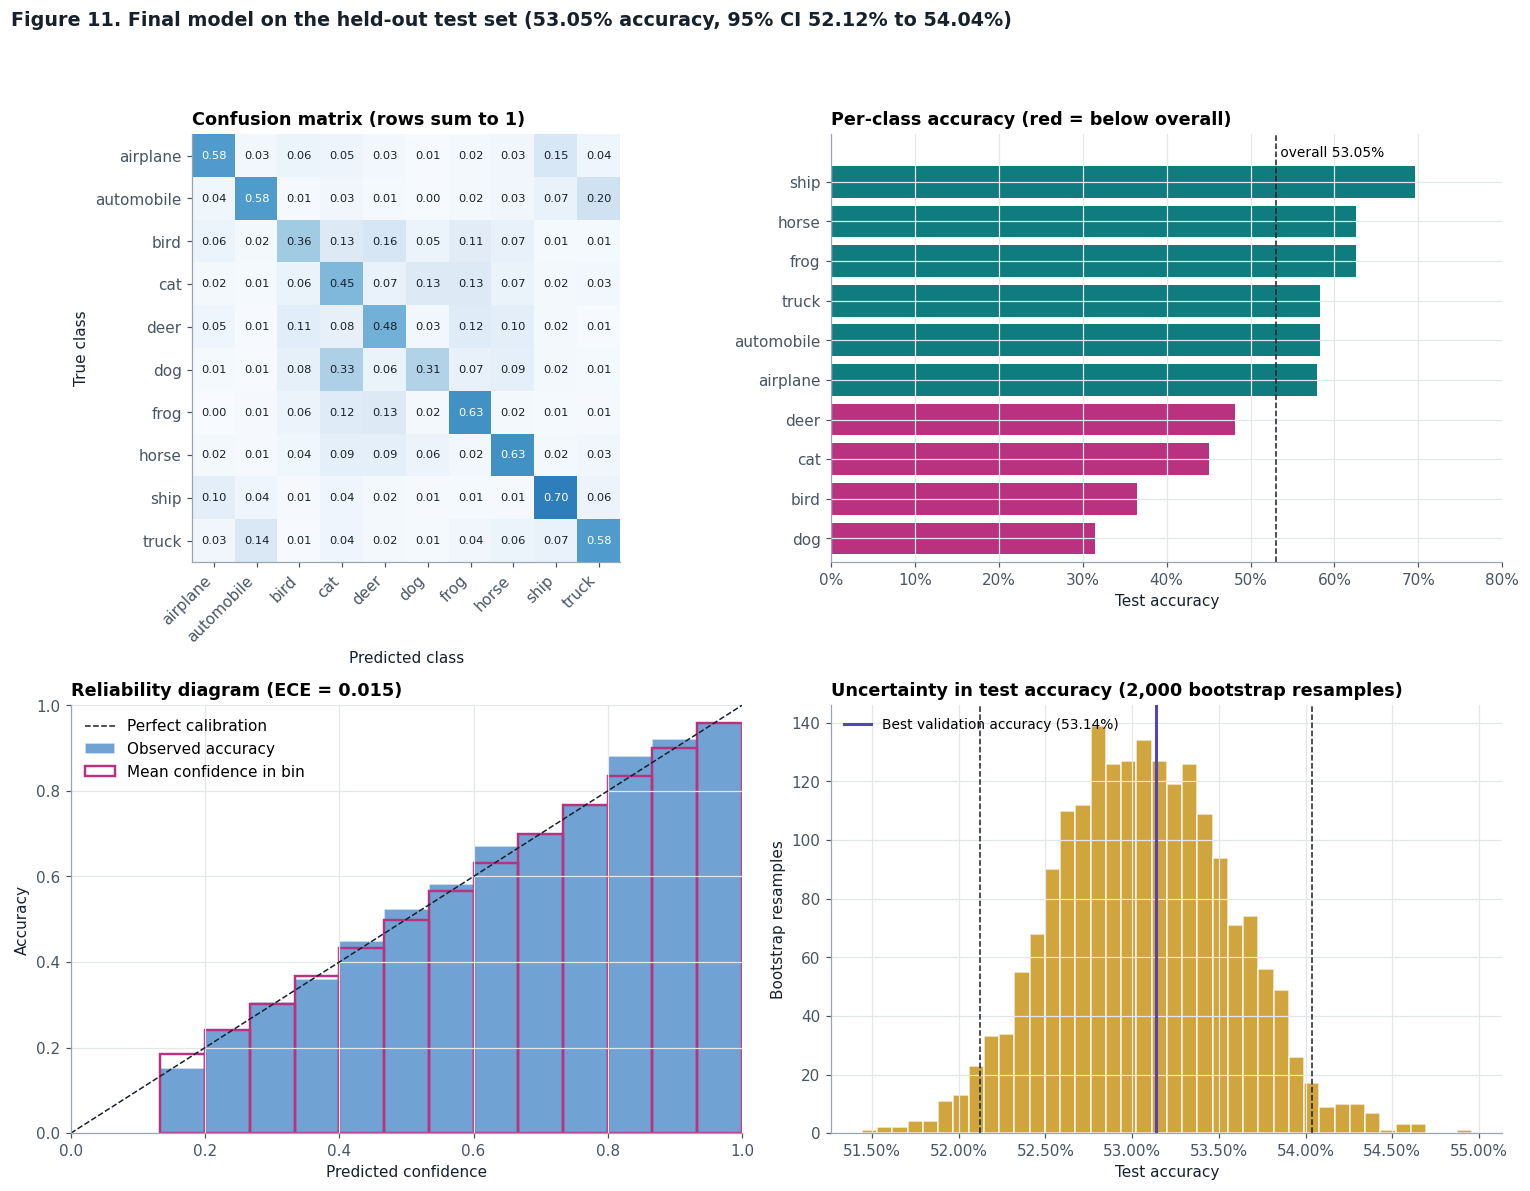

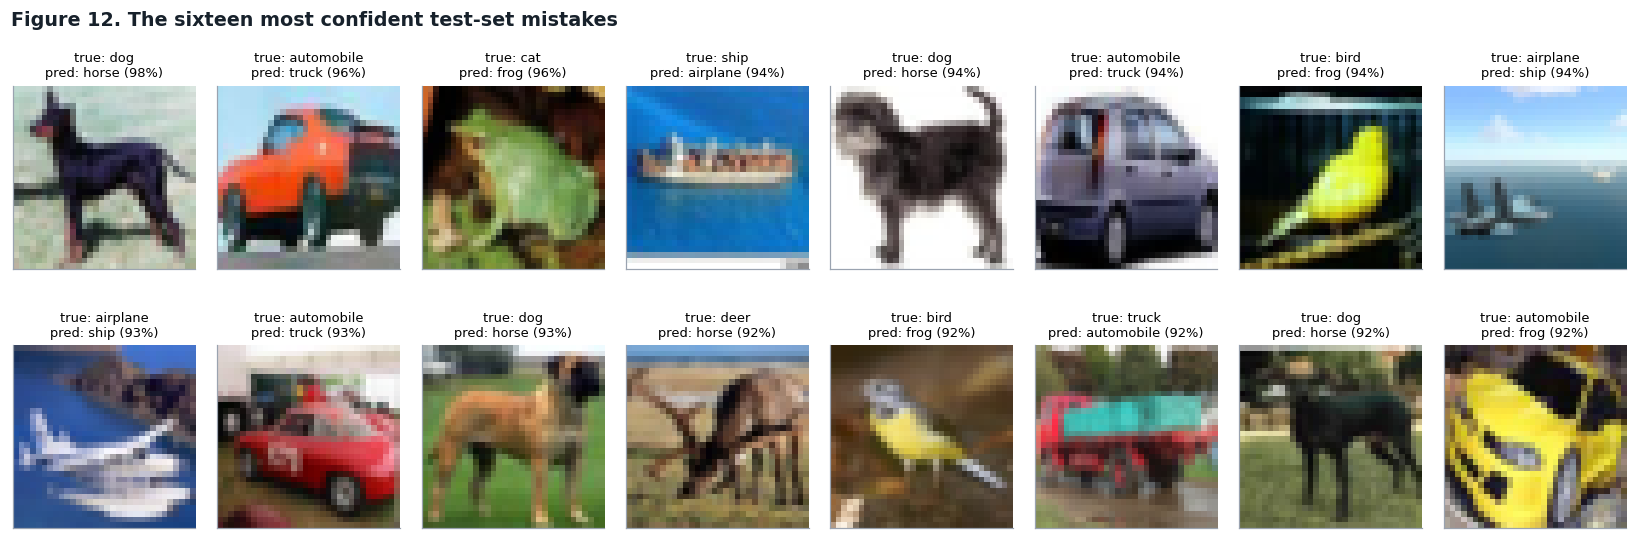

In [27]:
# Figure 11: where the final model succeeds and fails on the test set
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
ax = axes[0, 0]
cmn = cm / cm.sum(1, keepdims=True)
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color="white" if cmn[i, j] > 0.5 else PALETTE["ink"])
ax.set_xticks(range(10), CLASS_NAMES, rotation=45, ha="right"); ax.set_yticks(range(10), CLASS_NAMES); ax.grid(False)
ax.set(xlabel="Predicted class", ylabel="True class", title="Confusion matrix (rows sum to 1)")

ax = axes[0, 1]
order_c = np.argsort(per_class)
ax.barh([CLASS_NAMES[i] for i in order_c], per_class[order_c],
        color=[PALETTE["bayes"] if per_class[i] >= test_acc else PALETTE["alert"] for i in order_c])
ax.axvline(test_acc, color=PALETTE["ink"], ls="--", lw=1)
ax.text(test_acc, 9.55, f" overall {pct(test_acc)}", fontsize=9, va="bottom")
ax.set_xlim(0, min(1.0, per_class.max() * 1.15)); ax.set_ylim(-0.6, 10.2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(xlabel="Test accuracy", title="Per-class accuracy (red = below overall)")

ax = axes[1, 0]
ax.plot([0, 1], [0, 1], color=PALETTE["ink"], ls="--", lw=1, label="Perfect calibration")
ax.bar(calib["lo"], calib["accuracy"], width=calib["hi"] - calib["lo"], align="edge", color=PALETTE["bs128"], alpha=0.8,
       edgecolor="white", label="Observed accuracy")
ax.bar(calib["lo"], calib["confidence"], width=calib["hi"] - calib["lo"], align="edge", fill=False,
       edgecolor=PALETTE["alert"], lw=1.6, label="Mean confidence in bin")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Predicted confidence", ylabel="Accuracy", title=f"Reliability diagram (ECE = {ece:.3f})")
ax.legend(loc="upper left")

ax = axes[1, 1]
ax.hist(boots, bins=40, color=PALETTE["final"], alpha=0.85, edgecolor="white")
for v in (ci_lo, ci_hi):
    ax.axvline(v, color=PALETTE["ink"], ls="--", lw=1)
ax.axvline(FINAL["best_val_acc"], color=PALETTE["bn"], lw=2, label=f"Best validation accuracy ({pct(FINAL['best_val_acc'])})")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(xlabel="Test accuracy", ylabel="Bootstrap resamples", title="Uncertainty in test accuracy (2,000 bootstrap resamples)")
ax.legend(loc="upper left", fontsize=9)
finish(fig, f"Figure 11. Final model on the held-out test set ({pct(test_acc)} accuracy, 95% CI {pct(ci_lo)} to {pct(ci_hi)})")

# Figure 12: the model's most confident mistakes
wrong = np.where(~test_correct)[0]
worst = wrong[np.argsort(-test_probs[wrong].max(1))][:16]
fig, axes = plt.subplots(2, 8, figsize=(15, 4.9), gridspec_kw={"hspace": 0.42, "wspace": 0.1, "top": 0.84, "bottom": 0.02, "left": 0.01, "right": 0.99})
for ax, i in zip(axes.flat, worst):
    ax.imshow(X_test_raw[i]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[test_pred[i]]} ({test_probs[i].max():.0%})", fontsize=8.5, loc="center",
                 fontweight="normal")
finish(fig, "Figure 12. The sixteen most confident test-set mistakes", tight=False)

In [28]:
hid = cfg["hidden"]
cfg_text = describe(cfg)
top_name = top["name"]
def runs_word(k): return f"{k} run" if k == 1 else f"{k} runs"
if not eligible:
    sel_s = (f"The top validation score overall was {pct(top['best_val_acc'])} (`{top_name}`). It was flagged as {top['status']}, but no stable "
             f"run came within the noise band of it, so the rule keeps it; its validation score should be read with extra caution.")
    REF_WHY = "it is the best validation result, kept because no stable alternative came within the noise band of it"
elif FINAL is top:
    sel_s = (f"The top validation score overall was {pct(top['best_val_acc'])} (`{top_name}`). {runs_word(len(band))} lay within the noise band "
             f"of it and {len(eligible)} of them {'was' if len(eligible) == 1 else 'were'} stable; the preference for the fewest parameters picked "
             f"the top-scoring run itself ({FINAL['params']:,} parameters).")
    REF_WHY = "it is the best validation result and also the simplest stable model inside the noise band of that result"
else:
    ratio_p = top["params"] / FINAL["params"]
    trade = (f"for a network {ratio_p:.1f} times smaller" if ratio_p >= 1.1 else
             ("for a stable training curve" if top["status"] != "ok" else "for a slightly smaller network"))
    sel_s = (f"The top validation score overall was {pct(top['best_val_acc'])} (`{top_name}`"
             + (f", flagged as {top['status']})" if top["status"] != "ok" else ")")
             + f". {runs_word(len(band))} lay within the noise band of it, {len(eligible)} of them stable, and the rule picked "
             f"`{FINAL['name']}`, the stable run with the fewest parameters ({FINAL['params']:,}). It gives up "
             f"{pp(top['best_val_acc'] - FINAL['best_val_acc'])} of validation accuracy, inside the noise band, {trade}.")
    REF_WHY = "it is the simplest stable model that is statistically indistinguishable from the best validation result"
gap_vt = FINAL["best_val_acc"] - test_acc
gap_vt_s = (f"Test accuracy ({pct(test_acc)}) was {pp(abs(gap_vt))} {'below' if gap_vt > 0 else 'above'} the best validation accuracy "
            f"({pct(FINAL['best_val_acc'])}). "
            + (("A small drop is expected: the validation score was used to choose both the configuration and the epoch, so it is optimistically "
                "biased, while the test score is not." if gap_vt <= 0.02 else
                "Some drop is expected because the validation score was used for selection, but a gap of this size also suggests that "
                "repeated selection on the same 5,000 images has overfitted the validation set to a degree.") if gap_vt > 0 else
               "Test accuracy matching or exceeding validation suggests that the selection process did not overfit the validation set to any noticeable degree."))
conf_mean = float(test_probs.max(1).mean())
calib_s = (f"The expected calibration error was {ece:.3f}. On average the model was {'over' if conf_mean > test_acc else 'under'}confident by "
           f"{pp(abs(conf_mean - test_acc))} (mean confidence {pct(conf_mean)} against accuracy {pct(test_acc)}).")
note(FINAL_CONFIG_SENTENCE=(f"The selected model is `{FINAL['name']}` from {FINAL['group'].split(': ')[0]}: {cfg_text}, with the weights taken from "
                            f"epoch {FINAL['best_epoch']} of the {FINAL['epochs_run']} epochs it trained for."),
     FINAL_SELECTION_SENTENCE=sel_s, FINAL_VAL_ACC=pct(FINAL["best_val_acc"]), FINAL_TEST_ACC=pct(test_acc),
     FINAL_TEST_LOSS=f"{test_loss:.4f}", FINAL_CI=f"95% bootstrap confidence interval {pct(ci_lo)} to {pct(ci_hi)}",
     FINAL_GAP_SENTENCE=gap_vt_s,
     FINAL_CLASS_SENTENCE=(f"Per-class test accuracy ranged from {pct(per_class.min())} for {CLASS_NAMES[int(per_class.argmin())]} to "
                           f"{pct(per_class.max())} for {CLASS_NAMES[int(per_class.argmax())]}."),
     FINAL_CONFUSED_SENTENCE=("The most frequent confusions were " + join_and([f"{a} predicted as {b} ({c} images)" for c, a, b in top_conf[:3]]) + "."),
     FINAL_CALIB_SENTENCE=calib_s)
evidence("final model", ["FINAL_CONFIG_SENTENCE", "FINAL_SELECTION_SENTENCE", "FINAL_GAP_SENTENCE", "FINAL_CLASS_SENTENCE",
                         "FINAL_CONFUSED_SENTENCE", "FINAL_CALIB_SENTENCE"])

**Evidence from this run: final model**

- The selected model is `bayes_t2` from Step 6: 4 hidden layers of 256 units, with batch normalization, dropout 0.4, learning rate 0.0001 and batch size 32, with the weights taken from epoch 27 of the 30 epochs it trained for.
- The top validation score overall was 53.14% (`bayes_t2`). 1 run lay within the noise band of it and 1 of them was stable; the preference for the fewest parameters picked the top-scoring run itself (989,706 parameters).
- Test accuracy (53.05%) was 0.09 pp below the best validation accuracy (53.14%). A small drop is expected: the validation score was used to choose both the configuration and the epoch, so it is optimistically biased, while the test score is not.
- Per-class test accuracy ranged from 31.40% for dog to 69.60% for ship.
- The most frequent confusions were dog predicted as cat (327 images), automobile predicted as truck (196 images) and bird predicted as deer (161 images).
- The expected calibration error was 0.015. On average the model was underconfident by 1.20 pp (mean confidence 51.85% against accuracy 53.05%).

### Final model: results and interpretation

**Configuration.** {{FINAL_CONFIG_SENTENCE}}

**Why this one.** {{FINAL_SELECTION_SENTENCE}}

**Held-out performance.** On its single pass over the test set the model scored **{{FINAL_TEST_ACC}}** accuracy ({{FINAL_CI}}) with a test loss of {{FINAL_TEST_LOSS}}. {{FINAL_GAP_SENTENCE}}

**Where it fails.** {{FINAL_CLASS_SENTENCE}} {{FINAL_CONFUSED_SENTENCE}} Confusions of this kind are typical for a fully connected network on raw pixels. Without convolutional feature sharing, it leans heavily on global colour and layout, so classes that share backgrounds and palettes (animals on grass, vehicles on roads, ships and planes against blue) blur together, and fine shape cues such as ears, legs or wheels are hard to pick out.

**Can its confidence be trusted?** {{FINAL_CALIB_SENTENCE}} Modern neural networks are often miscalibrated (Guo et al., 2017), and this matters in practice: if the model's probabilities were used to decide when to defer to a human, a prediction made with 70% confidence should be right about 70% of the time. Temperature scaling fitted on the validation set would be the natural, inexpensive next step.

No hyperparameter, epoch or architecture choice was changed after these numbers were seen.

## Step 8: Comparative analysis

**Table 2. Summary comparison (test accuracy is reported for the final model only)**

,Best validation accuracy,Best epoch,Key observation,Test accuracy
Configuration,,,,
"Baseline (batch 128, no BN)",48.68%,21,"Peaks at epoch 21, then overfits; train–val ga...",—
"Best batch size (512, no BN)",49.78%,30,Selected by the noise-band rule; 88 updates pe...,—
Batch normalization (batch 512),40.64%,22,"BN did not speed up convergence, did not make ...",—
"Extension: no BN, lr 0.005",47.60%,24,"Small train–val gap, capacity-limited",—
"Extension: BN, lr 0.005",43.08%,5,Peaked early (epoch 5); noisy validation curve...,—
Best random search (trial 8),51.06%,23,Noisy validation curve (±2.2 pp per epoch),—
Best Bayesian optimization (trial 2),53.14%,27,"Small train–val gap, capacity-limited",—
Final selected model (bayes_t2),53.14%,27,Simplest stable model inside the noise band of...,53.05%


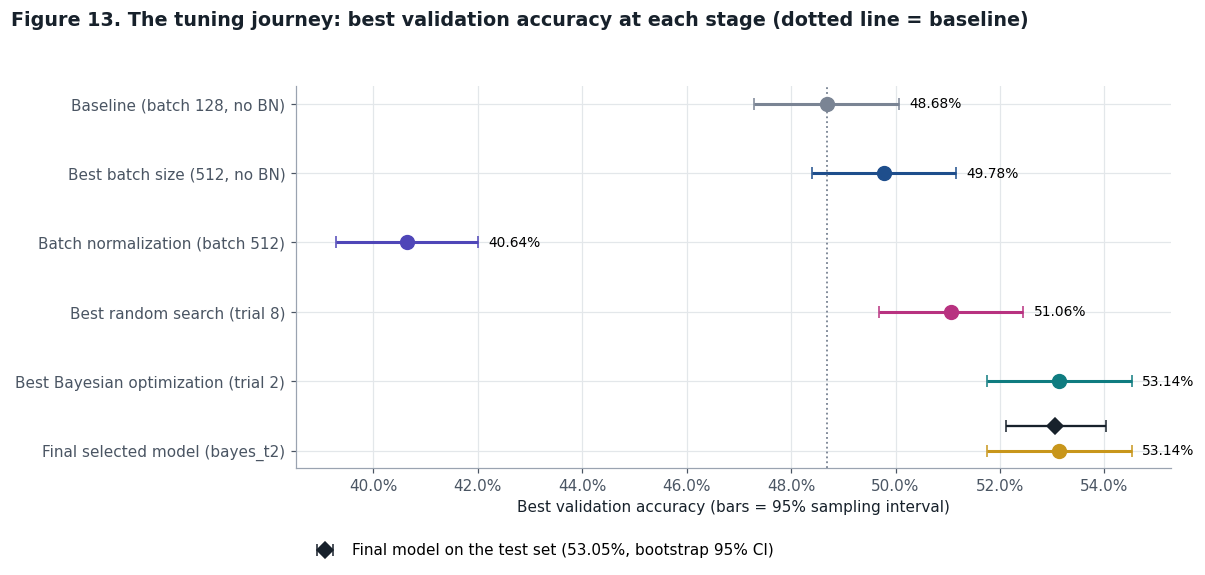

In [29]:
ext_rows = []
if RUN_LR_EXTENSION:
    ext_rows = [("Extension: no BN, lr 0.005", ext_plain, observe(ext_plain), "baseline"),
                ("Extension: BN, lr 0.005", ext_bn, observe(ext_bn), "bn")]
steps = [
    ("Baseline (batch 128, no BN)", base, f"Peaks at epoch {base['best_epoch']}, then overfits; train–val gap {pp(base['gap_at_end'], 1)} at epoch 30", "baseline"),
    (f"Best batch size ({SELECTED_BS}, no BN)", NOBN, f"Selected by the noise-band rule; {NOBN['updates_per_epoch']:,} updates per epoch", f"bs{SELECTED_BS}"),
    (f"Batch normalization (batch {SELECTED_BS})", bn, verdict_bn.replace("Taken together, batch normalization", "BN").rstrip("."), "bn"),
    *ext_rows,
    (f"Best random search (trial {rs_best['trial']})", rs_best, observe(rs_best), "random"),
    (f"Best Bayesian optimization (trial {bo_best['trial']})", bo_best, observe(bo_best), "bayes"),
    (f"Final selected model ({FINAL['name']})", FINAL,
     (f"Simplest stable model inside the noise band of the top score; test {pct(test_acc)}" if eligible
      else f"Top validation score (no stable run inside the noise band); test {pct(test_acc)}"), "final"),
]
table2 = pd.DataFrame([{"Configuration": lab, "Best validation accuracy": r["best_val_acc"], "Best epoch": r["best_epoch"],
                        "Key observation": obs, "Test accuracy": pct(test_acc) if r is FINAL and lab.startswith("Final") else "—"}
                       for lab, r, obs, _ in steps]).set_index("Configuration")
show_table(table2, "Table 2. Summary comparison (test accuracy is reported for the final model only)", {"Best validation accuracy": "{:.2%}"})

# Figure 13: the tuning journey with 95% sampling intervals
journey = [s_ for s_ in steps if not s_[0].startswith("Extension")]
fig, ax = plt.subplots(figsize=(11, 0.6 * len(journey) + 1.8))
labels_, ys = [], []
for k, (lab, r, _, ckey) in enumerate(journey[::-1]):
    acc = r["best_val_acc"]; half = 1.96 * math.sqrt(acc * (1 - acc) / N_VAL)
    color = PALETTE[ckey]
    ax.errorbar(acc, k, xerr=half, fmt="o", color=color, ms=9, capsize=4, lw=2)
    ax.text(acc + half + 0.002, k, pct(acc), va="center", fontsize=9)
    labels_.append(lab); ys.append(k)
ax.errorbar(test_acc, 0.36, xerr=[[test_acc - ci_lo], [ci_hi - test_acc]], fmt="D", color=PALETTE["ink"], ms=7, capsize=4,
            label=f"Final model on the test set ({pct(test_acc)}, bootstrap 95% CI)")
ax.axvline(base["best_val_acc"], color=PALETTE["baseline"], ls=":", lw=1.2)
ax.set_yticks(ys, labels_); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(xlabel="Best validation accuracy (bars = 95% sampling interval)", title="")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.16))
finish(fig, "Figure 13. The tuning journey: best validation accuracy at each stage (dotted line = baseline)")

In [30]:
_, _, p_gain = mcnemar(VAL_CORRECT[FINAL["name"]], VAL_CORRECT[base["name"]])
gain = FINAL["best_val_acc"] - base["best_val_acc"]
best_search = rs_best if rs_best["best_val_acc"] >= bo_best["best_val_acc"] else bo_best
ladder = [("choosing the batch size", NOBN["best_val_acc"] - base["best_val_acc"]),
          ("adding batch normalization", bn["best_val_acc"] - NOBN["best_val_acc"]),
          ("searching the full space (dropout, depth, width, learning rate)", best_search["best_val_acc"] - bn["best_val_acc"])]
lever = max(ladder, key=lambda kv: kv[1])
fixed = [r for r in RUNS.values() if not r["early_stopping"]]
peaked_early = [r for r in fixed if r["best_epoch"] <= r["epochs_run"] - 3]
kept_gain = np.mean([r["best_val_acc"] - r["history"]["val_accuracy"][-1] for r in fixed])
valid = [r for r in RUNS.values() if r["status"] != "failed"]
lo_r, hi_r = min(valid, key=lambda r: r["best_val_acc"]), max(valid, key=lambda r: r["best_val_acc"])
note(SUMMARY_GAIN_SENTENCE=(f"From the baseline's {pct(base['best_val_acc'])} to the final model's {pct(FINAL['best_val_acc'])}, tuning changed best "
                            f"validation accuracy by {spp(gain)}, {verdict(gain, p_gain)}."),
     SUMMARY_LEVER_SENTENCE=(f"Of the individual stages, {lever[0]} produced the largest single step ({spp(lever[1])}); the steps were "
                             + join_and([f"{spp(v)} for {k}" for k, v in ladder]) + "."),
     SUMMARY_PEAK_SENTENCE=(f"In {len(peaked_early)} of the {len(fixed)} fixed 30-epoch runs, validation accuracy peaked at least three epochs before "
                            f"training ended, and keeping the best-epoch weights instead of the last-epoch weights was worth {spp(kept_gain)} on average."),
     SUMMARY_RANGE_SENTENCE=(f"Across all {len(valid)} runs that did not fail, best validation accuracy spanned only {pct(lo_r['best_val_acc'])} "
                             f"to {pct(hi_r['best_val_acc'])}."))
evidence("summary", ["SUMMARY_GAIN_SENTENCE", "SUMMARY_LEVER_SENTENCE", "SUMMARY_PEAK_SENTENCE", "SUMMARY_RANGE_SENTENCE"])

**Evidence from this run: summary**

- From the baseline's 48.68% to the final model's 53.14%, tuning changed best validation accuracy by +4.46 pp, a difference that clears both the 1-pp noise band and a paired McNemar test (p < 0.001).
- Of the individual stages, searching the full space (dropout, depth, width, learning rate) produced the largest single step (+12.50 pp); the steps were +1.10 pp for choosing the batch size, -9.14 pp for adding batch normalization and +12.50 pp for searching the full space (dropout, depth, width, learning rate).
- In 5 of the 6 fixed 30-epoch runs, validation accuracy peaked at least three epochs before training ended, and keeping the best-epoch weights instead of the last-epoch weights was worth +2.30 pp on average.
- Across all 22 runs that did not fail, best validation accuracy spanned only 40.64% to 53.14%.

### Summary of the tuning process

{{SUMMARY_GAIN_SENTENCE}} {{SUMMARY_LEVER_SENTENCE}} Two broader findings stand out. First, *when* a model is evaluated mattered almost as much as *how* it was configured. {{SUMMARY_PEAK_SENTENCE}} Second, the gains from tuning are bounded by the architecture. {{SUMMARY_RANGE_SENTENCE}} That ceiling comes from the model family itself: a fully connected network on raw pixels has no built-in notion of spatial locality, and no learning rate or dropout setting can supply one.

## Beyond the brief: robustness, limitations and recommendations

Every configuration above was trained with a single seed, so part of any difference between runs is initialization luck. As a check that uses validation data only, I retrain the final configuration with three additional seeds under the same protocol it was selected with.

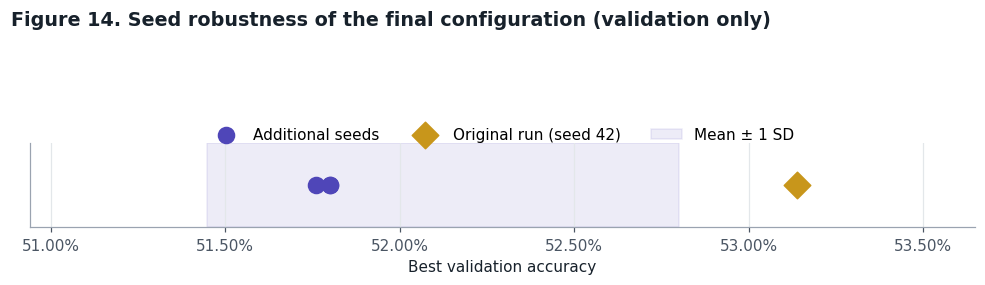

**Evidence from this run: robustness**

- Retraining the final configuration with seeds 7, 2024 and 31337 gave best validation accuracies of 51.80%, 51.76% and 51.80%. Together with the original run, the mean is 52.13% with a standard deviation of 0.68 pp, which is smaller than the 1-pp noise band. The original run ranked first of the four, a small illustration of the winner's curse: the configuration was selected partly on a favourable first seed.

In [31]:
if RUN_SEED_CHECK:
    seed_recs = [train_run(f"seed{s}_{FINAL['name']}", {**cfg, "hidden": tuple(cfg["hidden"])}, group="Robustness check",
                           early_stopping=FINAL["early_stopping"], seed=s, save=False) for s in SEED_CHECK_SEEDS]
    seed_accs = np.array([FINAL["best_val_acc"]] + [r["best_val_acc"] for r in seed_recs])
    fig, ax = plt.subplots(figsize=(9, 2.6))
    ax.scatter(seed_accs[1:], np.zeros(len(seed_recs)), s=110, color=PALETTE["bn"], label="Additional seeds", zorder=3)
    ax.scatter(seed_accs[0], 0, s=150, marker="D", color=PALETTE["final"], label=f"Original run (seed {SEED})", zorder=4)
    ax.axvspan(seed_accs.mean() - seed_accs.std(ddof=1), seed_accs.mean() + seed_accs.std(ddof=1), color=PALETTE["bn"], alpha=0.1, label="Mean ± 1 SD")
    ax.set_yticks([]); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlabel("Best validation accuracy")
    ax.margins(x=0.3); ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.35))
    finish(fig, "Figure 14. Seed robustness of the final configuration (validation only)")
    sd = seed_accs.std(ddof=1)
    rank = int(np.sum(seed_accs > seed_accs[0])) + 1
    rank_word = ["first", "second", "third", "fourth"][rank - 1]
    seed_s = (f"Retraining the final configuration with seeds {join_and(map(str, SEED_CHECK_SEEDS))} gave best validation accuracies of "
              f"{join_and([pct(a) for a in seed_accs[1:]])}. Together with the original run, the mean is {pct(seed_accs.mean())} with a "
              f"standard deviation of {pp(sd)}, which is {'smaller than' if sd < NOISE_BAND * 0.8 else ('about the size of' if sd < NOISE_BAND * 1.25 else 'larger than')} "
              f"the 1-pp noise band. The original run ranked {rank_word} of the four"
              + (", a small illustration of the winner's curse: the configuration was selected partly on a favourable first seed."
                 if rank == 1 and seed_accs[0] > seed_accs[1:].max() else ", so the original result was not simply a lucky draw."))
else:
    seed_s = "The seed robustness check was switched off for this run."
    seed_accs = np.array([FINAL["best_val_acc"]])
best_by_effect = list(pooled)[0]
note(SEED_SENTENCE=seed_s,
     REC_CONFIG_SENTENCE=(f"Within this search space, the evidence supports {describe(cfg)} as a sound default, and across all sixteen search "
                          f"trials {HP_LABELS[best_by_effect].lower()} was the hyperparameter with the widest spread in mean validation accuracy, "
                          f"so it is the first one I would tune more finely."))
evidence("robustness", ["SEED_SENTENCE"])

### Robustness check

{{SEED_SENTENCE}}

### Limitations and threats to validity

- **One seed per configuration.** Apart from the check above, each configuration was trained once. Rankings between configurations that differ by less than the seed-to-seed spread should be read as ties (Bouthillier et al., 2021).
- **Validation reuse.** More than twenty runs were compared on the same 5,000 images, and each run's best epoch was also chosen on them. That makes the best validation score optimistic, which is exactly why the test set was kept for a single final check.
- **Small search budget.** Eight trials per method cover under 2% of a 432-point grid. The comparison between search methods is a fair comparison *at this budget*, not a general verdict on the methods.
- **Fixed epoch cap and patience.** A 30-epoch cap with a patience of 8 favours configurations that learn quickly; very small learning rates are judged before they have finished converging.
- **Hardware-dependent timing.** Wall-clock times depend on the GPU, driver and input pipeline. The ratios between settings carry over to other machines better than the absolute seconds do.

### Recommendations

**For this model on this task.** {{REC_CONFIG_SENTENCE}} If I trained one more fully connected model on CIFAR-10, I would keep batch normalization, moderate dropout and best-epoch checkpointing, and add a learning-rate schedule such as cosine annealing (Loshchilov & Hutter, 2017) so that a higher initial rate can be used without late-training noise.

**For the tuning process.** With a larger budget I would (1) use multi-fidelity search such as Hyperband, which spends a few epochs on many configurations and full training only on the promising ones (Li et al., 2018); (2) search the learning rate on a continuous log scale instead of four fixed values; and (3) rerun the top few configurations over several seeds before declaring a winner.

**For real accuracy gains.** The largest lever is not a hyperparameter at all. Convolutional layers that share weights across image positions, together with simple data augmentation such as random crops and horizontal flips, are the standard way past the ceiling seen here (Goodfellow et al., 2016). Tuning gets the most out of an architecture; it cannot make up for the wrong one.

## Export results for the Streamlit dashboard

The cell below writes every run's history, the search tables, the final evaluation, the test predictions and all figures to `results/`, and bundles them into `results.zip`. Unzip it into the repository root, then run `make report` to build `REPORT.md` and `make app` to open the dashboard.

In [32]:
(RESULTS_DIR / "runs.json").write_text(json.dumps(list(RUNS.values()), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
pd.DataFrame([{"method": r["method"], "trial": r["trial"], "phase": r["phase"], **r["hp"],
               "best_val_acc": r["best_val_acc"], "best_epoch": r["best_epoch"], "epochs_run": r["epochs_run"],
               "status": r["status"], "observation": observe(r), "total_time": r["total_time"], "params": r["params"],
               "jitter_pp": 100 * r["jitter"], "name": r["name"]} for r in ALL_TRIALS]).to_csv(RESULTS_DIR / "search_trials.csv", index=False)
final_info = {
    "name": FINAL["name"], "group": FINAL["group"], "config": cfg, "description": describe(cfg), "params": FINAL["params"],
    "best_epoch": FINAL["best_epoch"], "epochs_run": FINAL["epochs_run"], "best_val_acc": FINAL["best_val_acc"],
    "test_acc": test_acc, "test_loss": test_loss, "ci": [float(ci_lo), float(ci_hi)], "ece": float(ece),
    "per_class": per_class.tolist(), "confusion": cm.tolist(), "calibration": calib.to_dict("records"),
    "bootstrap": boots.tolist(), "eligible": [r["name"] for r in eligible], "top_run": top["name"],
    "selected_batch_size": SELECTED_BS, "noise_band": NOISE_BAND, "seed_accs": seed_accs.tolist(),
    "class_names": CLASS_NAMES, "hardware": HARDWARE, "date": time.strftime("%Y-%m-%d"),
    "versions": {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__,
                 "optuna": optuna.__version__, "numpy": np.__version__},
    "total_train_minutes": sum(r["total_time"] for r in RUNS.values()) / 60,
}
(RESULTS_DIR / "final.json").write_text(json.dumps(final_info, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
np.savez_compressed(RESULTS_DIR / "test_predictions.npz", y_true=y_test, probs=test_probs.astype("float32"), images=X_test_raw)
shutil.copy(RESULTS_DIR / "weights" / f"{FINAL['name']}.weights.h5", RESULTS_DIR / "final_model.weights.h5")

with zipfile.ZipFile("results.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for p in RESULTS_DIR.rglob("*"):
        if p.is_file() and "weights" not in p.parts:
            zf.write(p, p.as_posix())
print("Saved:", sorted(p.name for p in RESULTS_DIR.iterdir()))
try:
    from google.colab import files
    files.download("results.zip")
except ImportError:
    pass

Saved: ['class_counts.csv', 'data_samples.npz', 'figures', 'final.json', 'final_model.weights.h5', 'narrative.json', 'runs.json', 'search_trials.csv', 'test_predictions.npz', 'weights']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# Evidence used in the final reflection
J = {b: 100 * BS_RUNS[b]["jitter"] for b in BATCH_SIZES}
A = {b: pct(BS_RUNS[b]["best_val_acc"]) for b in BATCH_SIZES}
flagged = [r for r in ALL_TRIALS if r["status"] != "ok"]
if flagged:
    lrs = pd.Series([r["hp"]["learning_rate"] for r in flagged]).value_counts()
    flag_s = (f"Of the {len(ALL_TRIALS)} search trials, {len(flagged)} {'was' if len(flagged) == 1 else 'were'} unstable or failed, "
              f"and {lrs.iloc[0]} of those used a learning rate of {lrs.index[0]:g}.")
else:
    flag_s = "None of the sixteen search trials met the instability or failure criteria."
drop_means = pd.DataFrame([{"d": r["hp"]["dropout"], "a": r["best_val_acc"]} for r in ALL_TRIALS]).groupby("d")["a"].mean()
note(
    REF_BS_SENTENCE=(f"Batch size mainly changed how training unfolded. At batch 32 the network made {BS_RUNS[32]['updates_per_epoch']:,} updates per epoch "
                     f"and its validation accuracy moved by about {J[32]:.2f} pp from epoch to epoch; at batch 512 it made "
                     f"{BS_RUNS[512]['updates_per_epoch']} updates and moved by {J[512]:.2f} pp. Best validation accuracies were {A[32]}, {A[128]} "
                     f"and {A[512]} for batch sizes 32, 128 and 512."),
    REF_BN_SENTENCE=(f"Batch normalization {'reached' if faster else 'did not reach'} the convergence target sooner "
                     f"(epoch {e1 or 'never'} against {e0 or 'never'}) and finished with a best validation accuracy of {pct(bn['best_val_acc'])} "
                     f"against {pct(NOBN['best_val_acc'])} without it."),
    REF_HP_SENTENCE=(f"Pooled over both searches, {HP_LABELS[best_by_effect].lower()} produced the widest spread in mean validation accuracy "
                     f"({pp(pooled[best_by_effect][0])}). {flag_s}"),
    REF_GEN_SENTENCE=(f"The unregularized baseline ended its 30 epochs with a {pp(base['gap_at_end'])} gap between training and validation accuracy, "
                      f"while the final model's gap at its selected epoch was {pp(FINAL['gap_at_best'])}. Across the sixteen search trials, mean best "
                      f"validation accuracy was " + join_and([f"{pct(v)} at dropout {k:g}" for k, v in drop_means.items()]) + "."),
    REF_SEARCH_SENTENCE=(f"Under the same eight-trial budget, random search's best trial reached {pct(rs_best['best_val_acc'])} and Bayesian "
                         f"optimization's reached {pct(bo_best['best_val_acc'])}, {verdict(d_search, p_search)}. Measured against a target of 1 pp "
                         f"below the overall best, {reach('random search', fs_r)}, and {reach('Bayesian optimization', fs_b)}."),
    REF_FINAL_SENTENCE=(f"The final model ({describe(cfg)}) reached {pct(FINAL['best_val_acc'])} on validation and {pct(test_acc)} on the test set "
                        f"(95% CI {pct(ci_lo)} to {pct(ci_hi)})"
                        + (f", and across four seeds its validation accuracy averaged {pct(seed_accs.mean())} (SD {pp(seed_accs.std(ddof=1))})."
                           if len(seed_accs) > 1 else ".")),
    REF_WHY_CLAUSE=REF_WHY,
)
display(Markdown(f"Narrative keys saved: {len(NARRATIVE)}. Download `results.zip`, unzip it in the repository root and run `make report`."))

Narrative keys saved: 61. Download `results.zip`, unzip it in the repository root and run `make report`.

## Final analysis and reflection

### Question 1: How did batch size, batch normalization and the searched hyperparameters affect training stability, convergence, validation performance and generalization?

**Training stability and convergence.** {{REF_BS_SENTENCE}} That pattern follows from what a mini-batch is. A gradient estimated from 32 images is a noisy sample of the full-data gradient, so each step is cheap and somewhat erratic, while an estimate from 512 images is smoother but arrives sixteen times less often per epoch (Masters & Luschi, 2018; Smith et al., 2018). Comparing runs by epoch alone would therefore have been misleading, which is why I also compared them by weight updates and by wall-clock time. {{REF_BN_SENTENCE}} This is consistent with the account in Santurkar et al. (2018): by keeping each layer's inputs on a stable scale, batch normalization makes the loss surface easier to descend, especially early in training. Among the searched hyperparameters, the learning rate interacts with both of these effects, because the step size and the gradient noise compound each other. {{REF_HP_SENTENCE}}

**Validation performance and generalization.** {{REF_GEN_SENTENCE}} Dropout was the only searched hyperparameter aimed squarely at generalization. It prevents units from co-adapting, which amounts to training an implicit ensemble of thinned networks (Srivastava et al., 2014). Batch size and batch normalization, by contrast, affected generalization mostly indirectly, through how quickly and how noisily the network reached the point where it began to memorize the training set. The most consistent generalization gain in the whole study came from something that is not a hyperparameter in the usual sense: evaluating each model at its best validation epoch rather than its last. Across every experiment, the improvements in validation accuracy were small next to the train–validation gaps, which tells me the binding constraint is the inductive bias of a fully connected architecture, not the optimizer settings.

### Question 2: How did random search and Bayesian optimization compare, and why is the final configuration appropriate?

**Random search versus Bayesian optimization.** {{REF_SEARCH_SENTENCE}} The result fits what each method is designed to do. Random search is a strong baseline when only a few hyperparameters matter, because it does not need to learn anything before it starts covering the space (Bergstra & Bengio, 2012). Bayesian optimization pays an upfront cost, here three warm-up trials, and its surrogate becomes useful only once it has seen enough good and bad configurations to tell them apart (Shahriari et al., 2016). With five guided trials, TPE had enough data to start steering but not enough to pull decisively ahead. Had I left Optuna's default warm-up of ten trials in place, both searches would have been random, which is a useful reminder that a tuner's settings matter as much as its name.

**Why the final configuration is appropriate.** {{REF_FINAL_SENTENCE}} It was chosen by a rule written down before the test set was opened; {{REF_WHY_CLAUSE}}; and its test score was measured exactly once, with an honest uncertainty interval around it. The brief asks for evidence-based model selection rather than the highest possible accuracy, and that combination of a principled selection rule, a single held-out confirmation and a stated margin of error is what makes this configuration the right choice for the task.

---

### References

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). Association for Computing Machinery. https://doi.org/10.1145/3292500.3330701

Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization. In *Advances in Neural Information Processing Systems 24* (pp. 2546–2554). Curran Associates.

Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305. https://www.jmlr.org/papers/v13/bergstra12a.html

Bouthillier, X., Delaunay, P., Bronzi, M., Trofimov, A., Nichyporuk, B., Szeto, J., Mohammadi Sepahvand, N., Raff, E., Madan, K., Voleti, V., Ebrahimi Kahou, S., Michalski, V., Arbel, T., Pal, C., Varoquaux, G., & Vincent, P. (2021). Accounting for variance in machine learning benchmarks. *Proceedings of Machine Learning and Systems, 3*, 747–769. https://arxiv.org/abs/2103.03098

Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895–1923. https://doi.org/10.1162/089976698300017197

Glorot, X., & Bengio, Y. (2010). Understanding the difficulty of training deep feedforward neural networks. In *Proceedings of the Thirteenth International Conference on Artificial Intelligence and Statistics* (pp. 249–256). PMLR.

Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press. https://www.deeplearningbook.org

Goyal, P., Dollár, P., Girshick, R., Noordhuis, P., Wesolowski, L., Kyrola, A., Tulloch, A., Jia, Y., & He, K. (2017). *Accurate, large minibatch SGD: Training ImageNet in 1 hour* (arXiv:1706.02677). arXiv. https://doi.org/10.48550/arXiv.1706.02677

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. In *Proceedings of the 34th International Conference on Machine Learning* (pp. 1321–1330). PMLR.

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7

Hoffer, E., Hubara, I., & Soudry, D. (2017). Train longer, generalize better: Closing the generalization gap in large batch training of neural networks. In *Advances in Neural Information Processing Systems 30* (pp. 1731–1741). Curran Associates.

Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. In *Proceedings of the 32nd International Conference on Machine Learning* (pp. 448–456). PMLR.

Keras Team. (n.d.). *BayesianOptimization tuner* [Software documentation]. KerasTuner. Retrieved October 20, 2026, from https://keras.io/keras_tuner/api/tuners/bayesian/

Keskar, N. S., Mudigere, D., Nocedal, J., Smelyanskiy, M., & Tang, P. T. P. (2017). On large-batch training for deep learning: Generalization gap and sharp minima. In *5th International Conference on Learning Representations*. https://arxiv.org/abs/1609.04836

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *3rd International Conference on Learning Representations*. https://arxiv.org/abs/1412.6980

Krizhevsky, A. (2009). *Learning multiple layers of features from tiny images* [Technical report]. University of Toronto. https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf

LeCun, Y. A., Bottou, L., Orr, G. B., & Müller, K.-R. (2012). Efficient BackProp. In G. Montavon, G. B. Orr, & K.-R. Müller (Eds.), *Neural networks: Tricks of the trade* (2nd ed., pp. 9–48). Springer. https://doi.org/10.1007/978-3-642-35289-8_3

Li, L., Jamieson, K., DeSalvo, G., Rostamizadeh, A., & Talwalkar, A. (2018). Hyperband: A novel bandit-based approach to hyperparameter optimization. *Journal of Machine Learning Research, 18*(185), 1–52. https://jmlr.org/papers/v18/16-558.html

Loshchilov, I., & Hutter, F. (2017). SGDR: Stochastic gradient descent with warm restarts. In *5th International Conference on Learning Representations*. https://arxiv.org/abs/1608.03983

Masters, D., & Luschi, C. (2018). *Revisiting small batch training for deep neural networks* (arXiv:1804.07612). arXiv. https://doi.org/10.48550/arXiv.1804.07612

Optuna Contributors. (n.d.). *optuna.samplers.TPESampler* [Software documentation]. Optuna. Retrieved October 20, 2026, from https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html

Prechelt, L. (1998). Early stopping—But when? In G. B. Orr & K.-R. Müller (Eds.), *Neural networks: Tricks of the trade* (pp. 55–69). Springer. https://doi.org/10.1007/3-540-49430-8_3

Raschka, S. (2018). *Model evaluation, model selection, and algorithm selection in machine learning* (arXiv:1811.12808). arXiv. https://doi.org/10.48550/arXiv.1811.12808

Santurkar, S., Tsipras, D., Ilyas, A., & Madry, A. (2018). How does batch normalization help optimization? In *Advances in Neural Information Processing Systems 31* (pp. 2483–2493). Curran Associates.

Shahriari, B., Swersky, K., Wang, Z., Adams, R. P., & de Freitas, N. (2016). Taking the human out of the loop: A review of Bayesian optimization. *Proceedings of the IEEE, 104*(1), 148–175. https://doi.org/10.1109/JPROC.2015.2494218

Smith, S. L., Kindermans, P.-J., Ying, C., & Le, Q. V. (2018). Don't decay the learning rate, increase the batch size. In *6th International Conference on Learning Representations*. https://arxiv.org/abs/1711.00489

Snoek, J., Larochelle, H., & Adams, R. P. (2012). Practical Bayesian optimization of machine learning algorithms. In *Advances in Neural Information Processing Systems 25* (pp. 2951–2959). Curran Associates.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(56), 1929–1958. https://jmlr.org/papers/v15/srivastava14a.html

Watanabe, S. (2023). *Tree-structured Parzen estimator: Understanding its algorithm components and their roles for better empirical performance* (arXiv:2304.11127). arXiv. https://doi.org/10.48550/arXiv.2304.11127